**Universidade Federal do Rio Grande do Norte**

**Disciplina:** PPGEEC2327 - Tópicos Especiais em Processamento Inteligente da Informação

**Discente:** José Augusto Agripino de Oliveira

# Deconvolução cega com redes neurais recorrentes (RNN)

Laboratório: [Blind Deconvolution by Vanilla Recurrent Neural Network](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.CNN.RNN/RNN_lab.html) (S. Feng).

Um traço sísmico é modelado como a convolução da refletividade $r(t)$ com a wavelet $w(t)$:

$$x(t) = (w * r)(t) = \sum_k w(k)\,r(t-k).$$

A **deconvolução** faz o caminho inverso: recupera os *spikes* de $r$ a partir do sismograma $x$. Ela é **cega** porque a wavelet não é dada à rede. A RNN aprende o filtro inverso só a partir de pares (sismograma, refletividade).

O `RNN_deconv.m` do lab gera 2000 amostras de refletividade, com um spike de amplitude aleatória em $[-1, 1]$ a cada 20 amostras, e faz a convolução com uma Ricker de 1 Hz ($\Delta t = 0{,}1$ s). Depois treina `layrecnet(1, 10, 'trainlm')`: uma RNN com 10 neurônios tanh, realimentados com atraso de uma amostra, e uma saída linear:

$$\mathbf h(t) = \tanh\big(\mathbf W x(t) + \mathbf R\,\mathbf h(t-1) + \mathbf b\big),\qquad \hat r(t) = \mathbf v^\top \mathbf h(t) + c .$$

**O que a seção 6 (*Questions*) do lab pede:**

1. Usar a refletividade como entrada e o sismograma como saída, isto é, usar a RNN para imitar a convolução. Como fica o resultado? Por quê?
2. Modificar a estrutura e os parâmetros da RNN e ver como eles mudam o resultado.
3. O lab usa a RNN convencional, sem portas. Uma calculadora binária treinada com LSTM está em `RNN_binary_lstm.m`.

A seção 1 reproduz o lab. As seções 2, 3 e 4 respondem às tarefas (1), (2) e (3), e a seção 5 reúne as conclusões.

In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')   # matrizes pequenas: com várias threads, o OpenBLAS ficou ~100x mais lento
import time
import warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import as_strided
from scipy.linalg import cho_factor, cho_solve
from IPython.display import display

warnings.filterwarnings('ignore', message='.*use of fork.*', category=DeprecationWarning)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'legend.frameon': False})
SEMENTES = range(5)                                   # inicializações por configuração
N_PROC = max(1, (os.cpu_count() or 2) - 2)            # processos de treino em paralelo (1 = em série)
if 'fork' not in mp.get_all_start_methods():
    N_PROC = 1
COR = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']   # mesma paleta dos exercícios anteriores
VERD = '#8a8984'                                      # série verdadeira (neutra) sob a previsão colorida
print(f'{N_PROC} processos de treino')

14 processos de treino


## 1. Reprodução do lab: deconvolução com a RNN

### 1.1 Wavelet e dados

O `ricker.m` devolve a Ricker a partir de $1/f$ segundos antes do pico. Com $f = 1$ Hz e $\Delta t = 0{,}1$ s, o pico fica na amostra 10. O corte `x_conv(11:2010)` do `RNN_deconv.m` alinha o pico da wavelet com cada spike. Assim:

$$x(t) = \sum_{k=-10}^{499} w(k)\, r(t-k),$$

ou seja, o sismograma no instante $t$ depende da refletividade até 10 amostras **no futuro**, $r(t+1), \dots, r(t+10)$.

wavelet: 510 amostras, pico na amostra 10; treino: 2000 amostras; teste: 200 amostras


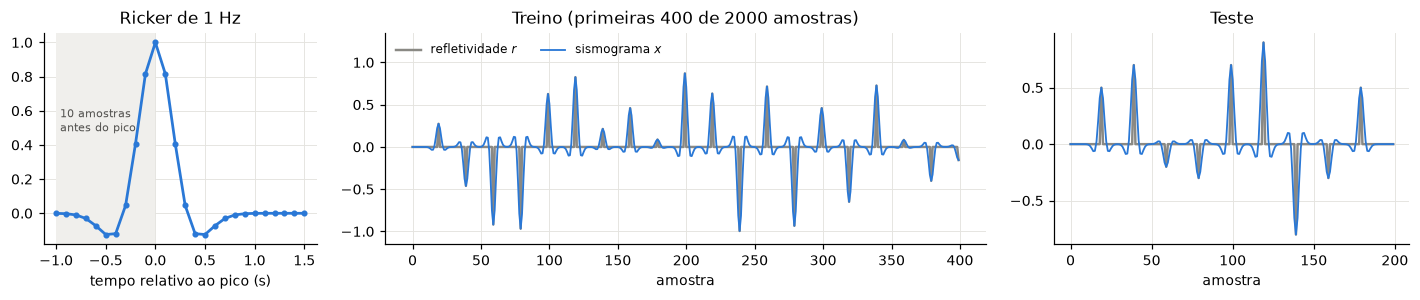

In [2]:
def ricker(np_, fr, dt):
    # tradução de ricker.m: Ricker de frequência fr, a partir de 1/fr s antes do pico
    npt = np_ * dt
    t = np.linspace(-npt / 2, npt / 2, int(round(npt / dt)) + 1)        # (-npt/2):dt:npt/2
    rick1 = (1 - t * t * fr**2 * np.pi**2) * np.exp(-t**2 * np.pi**2 * fr**2)
    return rick1[int(round(np_ / 2)) - int(round(1 / fr / dt)):np_]     # rick1(round(np/2)-round(1/fr/dt)+1 : np)


def sismograma(r, w, pico):
    # convolução cortada para que o pico da wavelet caia sobre cada spike (no .m: x_conv(11:2010), pico = 10)
    return np.convolve(w, r)[pico:pico + len(r)]


DT = 0.1
wav = ricker(1000, 1, DT)
PICO = int(np.argmax(wav))

# treino (RNN_deconv.m): spike de amplitude U(-1, 1) a cada 20 amostras
rng = np.random.default_rng(0)
r_tr = np.zeros(2000)
r_tr[19::20] = 2 * rng.random(100) - 1         # y(1, 20*ii) = 2*rand(1) - 1  (o MATLAB indexa a partir de 1)
x_tr = sismograma(r_tr, wav, PICO)

# teste (RNN_deconv.m): 9 spikes fixos
r_te = np.zeros(200)
r_te[19:180:20] = [0.5, 0.7, -0.2, -0.3, 0.7, 0.9, -0.8, -0.3, 0.5]
x_te = sismograma(r_te, wav, PICO)
print(f'wavelet: {len(wav)} amostras, pico na amostra {PICO}; treino: {len(x_tr)} amostras; teste: {len(x_te)} amostras')

fig, ax = plt.subplots(1, 3, figsize=(13, 2.8), gridspec_kw=dict(width_ratios=[1, 2.2, 1.3]))
tw = (np.arange(len(wav)) - PICO) * DT
ax[0].axvspan(tw[0], 0, color='#f0efec', lw=0)
ax[0].plot(tw[:26], wav[:26], color=COR[0], lw=1.8, marker='o', ms=3)
ax[0].text(-0.96, 0.62, '10 amostras\nantes do pico', color='#52514e', fontsize=7.5, va='top')
ax[0].set(title='Ricker de 1 Hz', xlabel='tempo relativo ao pico (s)')
for a, x, r, n, t in [(ax[1], x_tr, r_tr, 400, 'Treino (primeiras 400 de 2000 amostras)'), (ax[2], x_te, r_te, 200, 'Teste')]:
    a.plot(r[:n], color=VERD, lw=1.6, label='refletividade $r$')
    a.plot(x[:n], color=COR[0], lw=1.2, label='sismograma $x$')
    a.set(title=t, xlabel='amostra')
ax[1].set_ylim(-1.15, 1.35)
ax[1].legend(loc='upper left', ncol=2, fontsize=8)
plt.tight_layout()

### 1.2 A rede recorrente (`layrecnet` + `trainlm`)

A classe abaixo implementa:

* `propaga`: a propagação direta e, quando pedido, o jacobiano por RTRL. Para cada camada $l$:
  $\mathbf S_l(t) = \partial \mathbf h_l(t)/\partial\boldsymbol\theta = f'(\mathbf a_l)\odot\big[\partial \mathbf a_l/\partial\boldsymbol\theta|_{\text{direto}} + \mathbf W_l\,\mathbf S_{l-1}(t) + \sum_d \mathbf R_{l,d}\,\mathbf S_l(t-d)\big]$.
* `treinar`: Levenberg–Marquardt (`'lm'`, como o `trainlm`) ou gradiente descendente (`'gd'`, como o `traingd`). Também cuida da normalização, da divisão treino/validação e da parada antecipada.
* `atraso_saida = D`: a rede só precisa responder $\hat y(t-D)$ no instante $t$, ou seja, ela vê $D$ amostras "do futuro". O lab usa $D = 0$.

In [3]:
class MapMinMax:
    # mapminmax do MATLAB: leva [min, max] para [-1, 1]
    def __init__(self, v):
        self.lo, self.hi = float(v.min()), float(v.max())

    def __call__(self, v):
        return 2 * (v - self.lo) / (self.hi - self.lo) - 1

    def inv(self, v):
        return (v + 1) / 2 * (self.hi - self.lo) + self.lo


class RedeRecorrente:
    # layrecnet: camadas tanh com realimentação atrasada (atrasos) + saída linear

    def __init__(self, ocultas=(10,), atrasos=(1,), semente=0):
        self.H, self.atrasos = tuple(ocultas), tuple(atrasos)
        self.D = max(self.atrasos, default=0)
        self.n_in = [1] + list(self.H[:-1])                       # entradas de cada camada
        blocos = []
        for l, H in enumerate(self.H):
            blocos += [(f'W{l}', (H, self.n_in[l]))] + [(f'R{l}_{d}', (H, H)) for d in self.atrasos] + [(f'b{l}', (H,))]
        blocos += [('V', (1, self.H[-1])), ('c', (1,))]
        self.idx, o = {}, 0
        for nome, forma in blocos:
            self.idx[nome] = (o, forma)
            o += int(np.prod(forma))
        self.P = o                                                # número de parâmetros
        # inicialização tipo Nguyen-Widrow (initnw) nas camadas ocultas e U(-1, 1) na saída
        rng = np.random.default_rng(semente)
        th = np.zeros(self.P)
        for l, H in enumerate(self.H):
            fan = self.n_in[l] + H * len(self.atrasos)
            beta = 0.7 * H ** (1 / fan)
            M = rng.uniform(-1, 1, (H, fan))
            M *= beta / np.linalg.norm(M, axis=1, keepdims=True)
            self._set(th, f'W{l}', M[:, :self.n_in[l]])
            for k, d in enumerate(self.atrasos):
                self._set(th, f'R{l}_{d}', M[:, self.n_in[l] + k * H:self.n_in[l] + (k + 1) * H])
            self._set(th, f'b{l}', rng.uniform(-beta, beta, H))
        self._set(th, 'V', rng.uniform(-1, 1, (1, self.H[-1])))
        self._set(th, 'c', rng.uniform(-1, 1, 1))
        self.th, self.rho0 = th, self.raio_espectral(th)

    def _set(self, th, nome, val):
        o, forma = self.idx[nome]
        th[o:o + int(np.prod(forma))] = np.ravel(val)

    def _get(self, th, nome):
        o, forma = self.idx[nome]
        return th[o:o + int(np.prod(forma))].reshape(forma)

    def raio_espectral(self, th=None):
        # maior |autovalor| das matrizes de realimentação da 1ª camada
        th = self.th if th is None else th
        return max((np.abs(np.linalg.eigvals(self._get(th, f'R0_{d}'))).max() for d in self.atrasos), default=0.0)

    def propaga(self, th, u, jac=False):
        T, D, P, L = len(u), self.D, self.P, len(self.H)
        W = [self._get(th, f'W{l}') for l in range(L)]
        R = [{d: self._get(th, f'R{l}_{d}') for d in self.atrasos} for l in range(L)]
        b = [self._get(th, f'b{l}') for l in range(L)]
        V, c = self._get(th, 'V')[0], self._get(th, 'c')[0]
        hs = [np.zeros((T + D, H)) for H in self.H]               # D linhas de estado inicial nulo antes de t = 0
        U = u[:, None]
        for t in range(T):                                        # 1) propagação direta
            inp = U[t]
            for l in range(L):
                a = W[l] @ inp + b[l]
                for d in self.atrasos:
                    a += R[l][d] @ hs[l][t + D - d]
                inp = hs[l][t + D] = np.tanh(a)
        y = hs[-1][D:] @ V + c
        if not jac:
            return y
        # 2) jacobiano por RTRL. As views 'diag' apontam os termos diretos da/dW, da/dR e da/db dentro de dA:
        #    elemento [i, j] -> dA[i, deslocamento + i*n + j]
        diag = lambda A, o, n: as_strided(A[:, o:], shape=(A.shape[0], n), strides=(A.strides[0] + n * A.strides[1], A.strides[1]))
        dA = [np.empty((H, P)) for H in self.H]
        S = [np.zeros((D + 1, H, P)) for H in self.H]             # buffer circular com S(t-D) ... S(t)
        der = [1 - h[D:] ** 2 for h in hs]                        # tanh'(a) = 1 - h^2
        vW = [diag(dA[l], self.idx[f'W{l}'][0], self.n_in[l]) for l in range(L)]
        vR = [{d: diag(dA[l], self.idx[f'R{l}_{d}'][0], self.H[l]) for d in self.atrasos} for l in range(L)]
        vb = [diag(dA[l], self.idx[f'b{l}'][0], 1) for l in range(L)]
        J = np.zeros((T, P))
        oV, oc = self.idx['V'][0], self.idx['c'][0]
        for t in range(T):
            inp, S_inp = U[t], None
            for l in range(L):
                A = dA[l]
                if l > 0:
                    np.matmul(W[l], S_inp, out=A)
                elif not self.atrasos:
                    A.fill(0.0)
                for k, d in enumerate(self.atrasos):
                    if l == 0 and k == 0:
                        np.matmul(R[l][d], S[l][(t - d) % (D + 1)], out=A)
                    else:
                        A += R[l][d] @ S[l][(t - d) % (D + 1)]
                    vR[l][d] += hs[l][t + D - d]
                vW[l] += inp
                vb[l] += 1.0
                S_inp = S[l][t % (D + 1)]
                np.multiply(A, der[l][t][:, None], out=S_inp)
                inp = hs[l][t + D]
            np.matmul(V, S_inp, out=J[t])
            J[t, oV:oV + len(inp)] += inp
            J[t, oc] += 1.0
        return y, J

    def treinar(self, x, alvo, **opcoes):
        with np.errstate(all='ignore'):          # redes que divergem geram overflow; o treino trata esses casos
            return self._treinar(x, alvo, **opcoes)

    def _treinar(self, x, alvo, metodo='lm', epocas=500, lr=0.05, divisao=(0.70, 0.15, 0.15), max_fail=6,
                 mu=1e-3, mu_dec=0.1, mu_inc=10.0, mu_max=1e10, min_grad=1e-6, meta=1e-15, atraso_saida=0, semente=0):
        self.nx, self.ny, self.atraso_saida = MapMinMax(x), MapMinMax(alvo), atraso_saida
        T, Ds = len(x), atraso_saida
        u = np.concatenate([self.nx(x), np.zeros(Ds)])            # a saída da amostra n sai no instante n + Ds
        tn = self.ny(alvo)
        perm = np.random.default_rng(semente).permutation(T)      # dividerand, modo 'time'
        ntr = int(round(divisao[0] * T)) if divisao else T
        nva = int(round(divisao[1] * T)) if divisao else 0
        itr, iva = np.sort(perm[:ntr]), np.sort(perm[ntr:ntr + nva])
        mse = lambda o, ii: np.mean((o[ii + Ds] - tn[ii]) ** 2)
        th = self.th.copy()
        hist = {'treino': [], 'validacao': [], 'th': []}
        melhor, th_melhor, falhas, motivo = np.inf, th.copy(), 0, 'épocas'
        t0 = time.perf_counter()
        o, J = self.propaga(th, u, jac=True)
        for ep in range(epocas + 1):
            perf = mse(o, itr)
            pv = mse(o, iva) if len(iva) else perf
            hist['treino'].append(perf); hist['validacao'].append(pv); hist['th'].append(th.copy())
            if pv < melhor:
                melhor, th_melhor, falhas, self.epoca_melhor = pv, th.copy(), 0, ep
            else:
                falhas += 1
            Jt, e = J[itr + Ds], o[itr + Ds] - tn[itr]
            g = 2 * Jt.T @ e / len(itr)                           # gradiente do EQM
            if ep == epocas:
                break
            if not np.isfinite(perf):
                motivo = 'divergiu'; break
            if perf <= meta:
                motivo = 'meta'; break
            if np.linalg.norm(g) < min_grad:
                motivo = 'gradiente mínimo'; break
            if len(iva) and falhas >= max_fail:
                motivo = 'validação'; break
            if metodo == 'lm':
                JJ, Je, aceito = Jt.T @ Jt, Jt.T @ e, False
                while mu <= mu_max:                               # aumenta mu até o passo reduzir o erro
                    try:
                        dth = -cho_solve(cho_factor(JJ + mu * np.eye(self.P)), Je)
                    except (np.linalg.LinAlgError, ValueError):       # matriz não positiva definida ou com inf/NaN
                        mu *= mu_inc
                        continue
                    if mse(self.propaga(th + dth, u), itr) < perf:
                        th, mu, aceito = th + dth, mu * mu_dec, True
                        break
                    mu *= mu_inc
                if not aceito:
                    motivo = 'mu máximo'; break
            else:                                                 # traingd
                th = th - lr * g
            o, J = self.propaga(th, u, jac=True)
        self.th, self.hist, self.epocas, self.motivo = th_melhor, hist, ep, motivo
        self.val, self.tempo = melhor, time.perf_counter() - t0
        return self

    def __call__(self, x, th=None):
        th = self.th if th is None else th
        u = np.concatenate([self.nx(x), np.zeros(self.atraso_saida)])
        with np.errstate(all='ignore'):
            return self.ny.inv(self.propaga(th, u)[self.atraso_saida:])


nmse = lambda prev, alvo: float(np.sum((prev - alvo) ** 2) / np.sum(alvo ** 2))
melhor = lambda redes: min(redes, key=lambda r: r.val)          # escolha pela validação


def _treina(tarefa):
    nome, estrutura, treino, entrada, alvo, semente = tarefa
    return RedeRecorrente(semente=semente, **estrutura).treinar(entrada, alvo, semente=semente, **treino)


def treina_lote(configs, entrada=None, alvo=None, sementes=SEMENTES):
    # Treina cada configuração {nome: dict} a partir de todas as sementes, em paralelo.
    # Devolve {nome: [rede da semente 0, rede da semente 1, ...]}.
    tarefas = []
    for nome, cfg in configs.items():
        cfg = dict(cfg)
        e, a = cfg.pop('entrada', entrada), cfg.pop('alvo', alvo)
        estrutura = {k: cfg.pop(k) for k in ('ocultas', 'atrasos') if k in cfg}
        tarefas += [(nome, estrutura, cfg, e, a, s) for s in sementes]
    # as tarefas mais demoradas primeiro, para os processos terminarem juntos
    custo = lambda t: RedeRecorrente(**t[1]).P * (8 if t[2].get('metodo') == 'gd' or 'divisao' in t[2] or t[2].get('atraso_saida', 0) >= 10 else 1)
    ordem = sorted(range(len(tarefas)), key=lambda i: -custo(tarefas[i]))
    if N_PROC > 1:
        with ProcessPoolExecutor(N_PROC, mp_context=mp.get_context('fork')) as ex:
            redes = list(ex.map(_treina, [tarefas[i] for i in ordem]))
    else:
        redes = [_treina(tarefas[i]) for i in ordem]
    saida = {nome: [None] * len(sementes) for nome in configs}
    for i, rede in zip(ordem, redes):
        saida[tarefas[i][0]][list(sementes).index(tarefas[i][5])] = rede
    return saida


def fmt(v):
    return f'{v:.4f}' if 1e-3 <= abs(v) < 100 else f'{v:.1e}'


def tabela_sementes(redes, ent_tr, alvo_tr, ent_te, alvo_te):
    esc = melhor(redes)
    return pd.DataFrame([{'semente': s, 'épocas': r.epocas, 'parada': r.motivo, 'EQM validação (normalizado)': fmt(r.val),
                          'NMSE treino': fmt(nmse(r(ent_tr), alvo_tr)), 'NMSE teste': fmt(nmse(r(ent_te), alvo_te)),
                          'tempo (s)': f'{r.tempo:.1f}', 'escolhida': '◀' if r is esc else ''}
                         for s, r in zip(SEMENTES, redes)]).set_index('semente')

Conferência do jacobiano por RTRL contra diferenças finitas centradas, em redes pequenas com estruturas diferentes:

In [4]:
rng_t = np.random.default_rng(1)
u_t = rng_t.uniform(-1, 1, 30)
for estrutura in [dict(), dict(ocultas=(4, 3), atrasos=(1, 2)), dict(atrasos=())]:
    rede = RedeRecorrente(semente=3, **estrutura)
    th = rede.th + rng_t.normal(0, 0.3, rede.P)
    _, J = rede.propaga(th, u_t, jac=True)
    Jn = np.stack([(rede.propaga(th + e, u_t) - rede.propaga(th - e, u_t)) / 2e-6 for e in 1e-6 * np.eye(rede.P)], 1)
    print(f'{str(estrutura or "lab"):38s} {rede.P:4d} parâmetros   max |J_RTRL - J_numérico| = {np.abs(J - Jn).max():.1e}')

lab                                     131 parâmetros   max |J_RTRL - J_numérico| = 4.0e-10
{'ocultas': (4, 3), 'atrasos': (1, 2)}   77 parâmetros   max |J_RTRL - J_numérico| = 2.2e-10
{'atrasos': ()}                          31 parâmetros   max |J_RTRL - J_numérico| = 6.1e-10


### 1.3 Treino e resultado

`layrecnet(1, 10, 'trainlm')` treinada a partir de 5 inicializações:

In [5]:
t0 = time.perf_counter()
lab = treina_lote({'lab': {}}, x_tr, r_tr)['lab']
base = melhor(lab)
print(f'{len(lab)} redes treinadas em {time.perf_counter() - t0:.0f} s; {base.P} parâmetros')
display(tabela_sementes(lab, x_tr, r_tr, x_te, r_te))

5 redes treinadas em 13 s; 131 parâmetros


,épocas,parada,EQM validação (normalizado),NMSE treino,NMSE teste,tempo (s),escolhida
semente,,,,,,,
0,29,validação,0.0020,0.0718,0.2166,2.9,
1,144,validação,6.4e-05,0.0017,0.0048,12.5,
2,37,validação,6.4e-05,0.0039,0.0038,3.8,
3,92,validação,1.2e-04,0.0048,0.0048,8.1,
4,54,validação,4.9e-05,0.0021,0.0143,5.1,◀


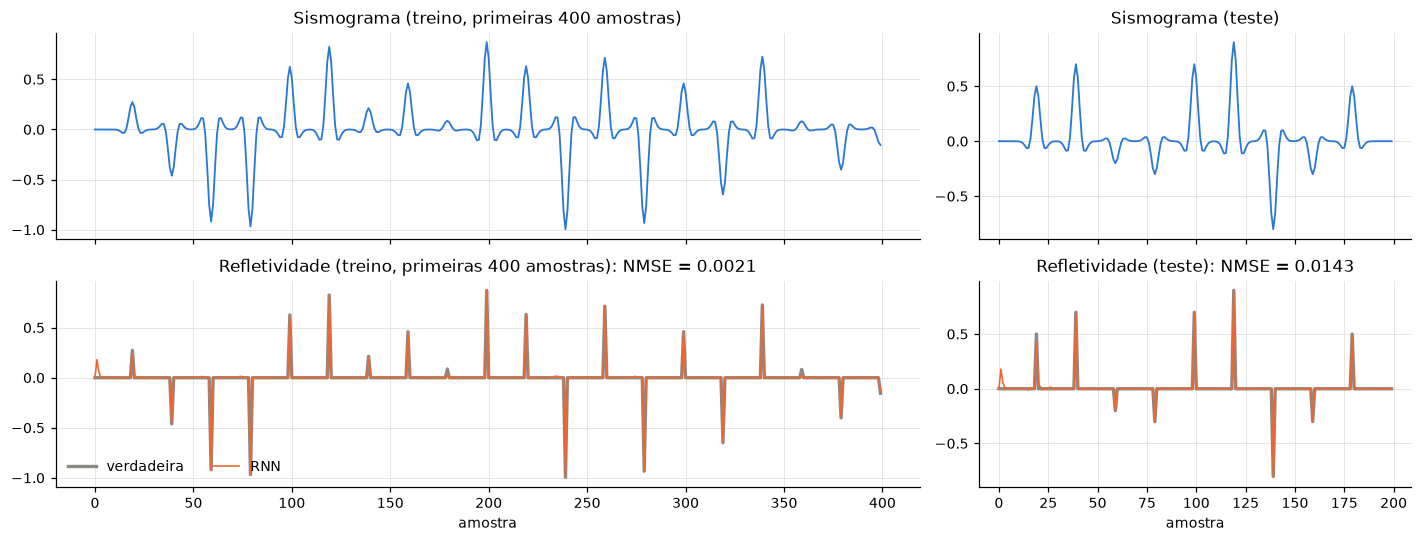

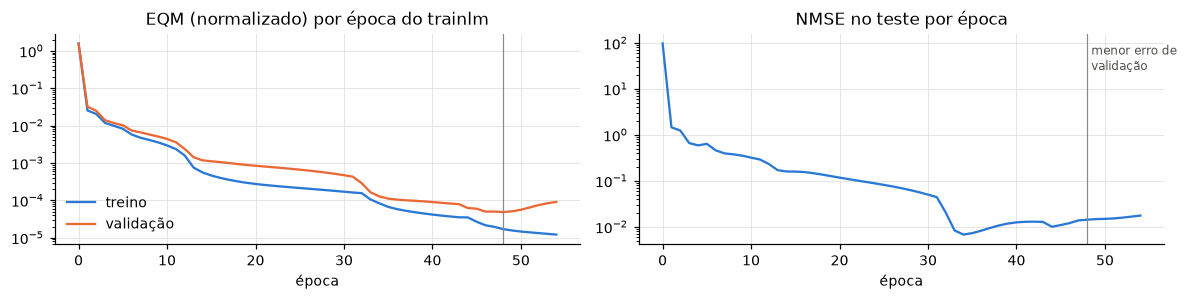

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 5), sharex='col', gridspec_kw=dict(width_ratios=[2, 1]))
for j, (x, r, n, nome) in enumerate([(x_tr, r_tr, 400, 'treino, primeiras 400 amostras'), (x_te, r_te, 200, 'teste')]):
    ax[0, j].plot(x[:n], color=COR[0], lw=1.2)
    ax[0, j].set_title(f'Sismograma ({nome})')
    ax[1, j].plot(r[:n], color=VERD, lw=2.2, label='verdadeira')
    ax[1, j].plot(base(x)[:n], color=COR[1], lw=1.1, label='RNN')
    ax[1, j].set(title=f'Refletividade ({nome}): NMSE = {nmse(base(x), r):.4f}', xlabel='amostra')
ax[1, 0].legend(loc='lower left', ncol=2)
plt.tight_layout()

fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ep = np.arange(len(base.hist['treino']))
ax[0].semilogy(ep, base.hist['treino'], color=COR[0], lw=1.5, label='treino')
ax[0].semilogy(ep, base.hist['validacao'], color=COR[1], lw=1.5, label='validação')
ax[0].axvline(base.epoca_melhor, color=VERD, lw=0.8)
ax[0].set(title='EQM (normalizado) por época do trainlm', xlabel='época')
ax[0].legend()
nm_ep = [nmse(base(x_te, th), r_te) for th in base.hist['th']]
ax[1].semilogy(ep, nm_ep, color=COR[0], lw=1.5)
ax[1].axvline(base.epoca_melhor, color=VERD, lw=0.8)
ax[1].text(base.epoca_melhor, nm_ep[0], ' menor erro de\n validação', color='#52514e', fontsize=8, va='top')
ax[1].set(title='NMSE no teste por época', xlabel='época')
plt.tight_layout()

**Resultado.** A rede escolhida pela validação (semente 4) recupera os nove spikes do teste com posição, sinal e amplitude quase exatos: NMSE de 0,0143 no teste e 0,0021 no treino. É o resultado da Fig. 1 do lab. Três observações:

* **Transitório inicial.** Nas primeiras amostras a saída vale cerca de 0,18, embora não haja spike. O estado começa em $\mathbf h(0) = \mathbf 0$, que não é o estado de equilíbrio da rede para entrada nula, e a recorrência leva algumas amostras para se acomodar.
* **Variação entre inicializações.** O NMSE de teste vai de 0,0038 a 0,22 entre as 5 sementes; a semente 0 parou cedo, após 29 épocas, num mínimo pior. A validação também não escolheu a melhor rede no teste: escolheu a semente 4 (0,0143), e não a semente 2 (0,0038). O motivo é que o `dividerand` no modo `'time'` sorteia **instantes da própria sequência de treino** para a validação. Ela mede a interpolação dentro dessa sequência, não a generalização para uma sequência nova. As curvas mostram o mesmo: o NMSE de teste é mínimo perto da época 34, antes do mínimo da validação (época 48).
* **Convergência.** O Levenberg–Marquardt reduz o EQM em 5 ordens de grandeza em cerca de 50 épocas. A parada antecipada encerra o treino depois de 6 épocas seguidas de piora na validação.

## 2. Tarefa (1): a RNN imitando a convolução

Agora a entrada é a refletividade e o alvo é o sismograma. A rede, os dados e o treino são os mesmos da seção 1.

Para explicar o resultado, já são treinadas também versões com **atraso de saída** $D = 5$ e $D = 10$: no instante $t$, a rede responde $\hat x(t-D)$, ou seja, ela pode ver $D$ amostras da refletividade além do instante que está prevendo. A seção 2.2 usa essas versões para testar a explicação.

In [7]:
t0 = time.perf_counter()
conv = treina_lote({D: dict(atraso_saida=D) for D in (0, 5, 10)}, r_tr, x_tr)
print(f'{sum(map(len, conv.values()))} redes treinadas em {time.perf_counter() - t0:.0f} s')
conv0 = melhor(conv[0])
display(tabela_sementes(conv[0], r_tr, x_tr, r_te, x_te))

15 redes treinadas em 45 s


,épocas,parada,EQM validação (normalizado),NMSE treino,NMSE teste,tempo (s),escolhida
semente,,,,,,,
0,2,mu máximo,0.4649,9.5556,10.9299,0.3,
1,29,validação,0.0097,0.3183,0.3164,3.6,◀
2,14,validação,0.0139,0.3205,0.3228,2.0,
3,11,validação,0.0208,0.3212,0.3174,1.4,
4,1,mu máximo,0.9282,19.9391,25.6160,0.2,


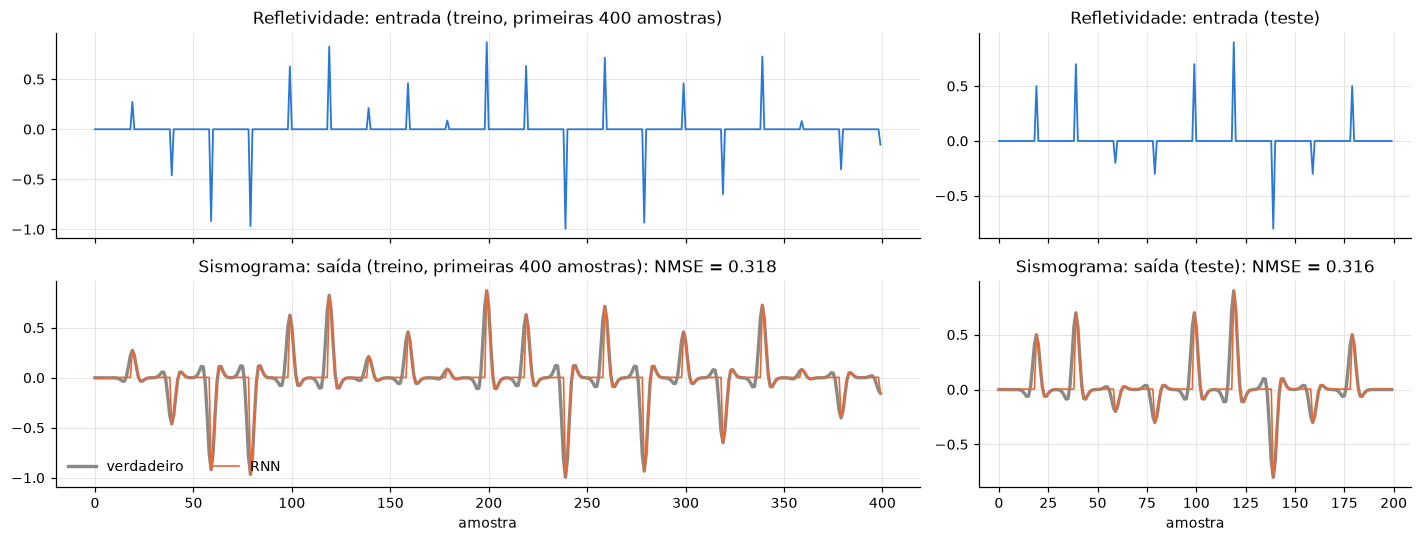

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 5), sharex='col', gridspec_kw=dict(width_ratios=[2, 1]))
for j, (x, r, n, nome) in enumerate([(x_tr, r_tr, 400, 'treino, primeiras 400 amostras'), (x_te, r_te, 200, 'teste')]):
    ax[0, j].plot(r[:n], color=COR[0], lw=1.2)
    ax[0, j].set_title(f'Refletividade: entrada ({nome})')
    ax[1, j].plot(x[:n], color=VERD, lw=2.2, label='verdadeiro')
    ax[1, j].plot(conv0(r)[:n], color=COR[1], lw=1.1, label='RNN')
    ax[1, j].set(title=f'Sismograma: saída ({nome}): NMSE = {nmse(conv0(r), x):.3f}', xlabel='amostra')
ax[1, 0].legend(loc='lower left', ncol=2)
plt.tight_layout()

**Resultado.** Duas das 5 inicializações falharam logo no início, por "mu máximo", com NMSE de 10 a 25 (a seção 3.6 explica essas falhas). As outras 3 convergiram para praticamente o mesmo ponto: **NMSE ≈ 0,32** no treino e no teste. É um erro 20 a 80 vezes maior que o da deconvolução, embora a convolução seja o problema "fácil": direto, linear e bem posto.

A figura mostra onde está o erro. A RNN acerta o pico e todo o trecho **depois** de cada spike. Na janela **antes** do spike, onde o sismograma verdadeiro tem o lobo lateral negativo e o flanco de subida do lobo principal, a saída fica parada em zero e só "salta" no instante exato do spike.

### 2.1 Por quê? Causalidade

Uma RNN unidirecional é **causal**: $\mathbf h(t)$ depende só de $r(0), \dots, r(t)$. Já o sismograma depende de $r(t+1), \dots, r(t+10)$, porque o pico da Ricker de fase zero cai sobre o spike e a "subida" da wavelet (o lobo lateral negativo e o flanco do lobo principal) acontece **antes** do spike.

Qual é então a melhor previsão causal possível? A rede até pode saber *quando* virá o próximo spike, pois eles são periódicos. Mas a amplitude dele é sorteada em $U(-1, 1)$, com média zero e independente do passado. Logo:

$$\mathbb E\big[x(t)\,\big|\,r(0..t)\big] = \sum_{k \ge 0} w(k)\,r(t-k) = (w_c * r)(t),\qquad w_c(k) = \begin{cases} w(k), & k \ge 0\\ 0, & k < 0\end{cases}$$

Esse "limite causal" é a convolução com a **metade causal** da wavelet. Se a RNN for ótima, ela converge para ele. Com atraso de saída $D$, o limite passa a ser $w$ truncada em $k \ge -D$, e para $D \ge 10$ a wavelet inteira fica acessível.

,NMSE treino (RNN escolhida),NMSE teste (RNN escolhida),NMSE teste (mediana das 5),limite causal: NMSE treino,limite causal: NMSE teste,NMSE teste RNN vs limite causal
atraso de saída D,,,,,,
0,0.3183,0.3164,0.3228,0.3188,0.3177,4.1e-04
5,0.0024,0.0028,0.0023,0.0023,0.0023,5.5e-04
10,1.4e-06,2.1e-06,0.0020,0.0e+00,0.0e+00,2.1e-06


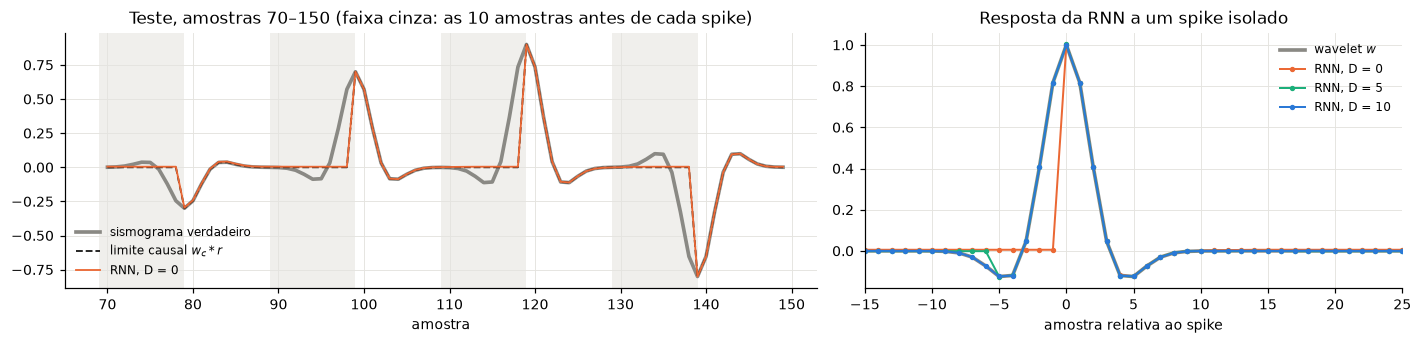

In [9]:
def limite_causal(r, D=0):
    wc = wav.copy()
    wc[:max(PICO - D, 0)] = 0                   # zera w(k) para k < -D
    return sismograma(r, wc, PICO)


linhas = []
for D, redes in conv.items():
    esc = melhor(redes)
    linhas.append({'atraso de saída D': D, 'NMSE treino (RNN escolhida)': fmt(nmse(esc(r_tr), x_tr)),
                   'NMSE teste (RNN escolhida)': fmt(nmse(esc(r_te), x_te)),
                   'NMSE teste (mediana das 5)': fmt(np.median([nmse(r(r_te), x_te) for r in redes])),
                   'limite causal: NMSE treino': fmt(nmse(limite_causal(r_tr, D), x_tr)),
                   'limite causal: NMSE teste': fmt(nmse(limite_causal(r_te, D), x_te)),
                   'NMSE teste RNN vs limite causal': fmt(nmse(esc(r_te), limite_causal(r_te, D)))})
display(pd.DataFrame(linhas).set_index('atraso de saída D'))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
s = slice(70, 150)
n = np.arange(200)[s]
ax[0].plot(n, x_te[s], color=VERD, lw=2.4, label='sismograma verdadeiro')
ax[0].plot(n, limite_causal(r_te)[s], color='#1a1a19', lw=1.2, ls='--', label='limite causal $w_c * r$')
ax[0].plot(n, conv0(r_te)[s], color=COR[1], lw=1.2, label='RNN, D = 0')
for k in np.flatnonzero(r_te[s]):
    ax[0].axvspan(n[k] - 10, n[k], color='#f0efec', lw=0, zorder=0)
ax[0].set(title='Teste, amostras 70–150 (faixa cinza: as 10 amostras antes de cada spike)', xlabel='amostra')
ax[0].legend(loc='lower left', fontsize=8)

# resposta ao impulso: um spike isolado de amplitude 0,8 na amostra 30
imp = np.zeros(80)
imp[30] = 0.8
k = np.arange(80) - 30
ax[1].plot(k, wav[np.clip(k + PICO, 0, len(wav) - 1)] * (k >= -PICO), color=VERD, lw=2.4, label='wavelet $w$')
for i, D in enumerate(conv):
    ax[1].plot(k, melhor(conv[D])(imp) / 0.8, color=COR[[1, 2, 0][i]], lw=1.3, marker='o', ms=2.5, label=f'RNN, D = {D}')
ax[1].set(title='Resposta da RNN a um spike isolado', xlabel='amostra relativa ao spike', xlim=(-15, 25))
ax[1].legend(fontsize=8)
plt.tight_layout()

**A explicação se confirma quantitativamente:**

* Com $D = 0$, o NMSE de teste da RNN (0,3164) é praticamente o do limite causal (0,3177), e a saída da RNN difere de $w_c * r$ por um NMSE de apenas $4\times10^{-4}$. Ou seja, **a RNN aprendeu a melhor resposta causal possível**. Os cerca de 32 % de erro são a energia da parte da wavelet que precede o pico, e nenhuma rede causal consegue prevê-la.
* A resposta ao impulso torna isso visível. Com $D = 0$, a saída é nula antes do spike e igual à Ricker a partir dele. Com $D = 5$, a rede começa a responder 5 amostras antes. Com $D = 10$, reproduz a wavelet inteira e o NMSE cai para $2\times10^{-6}$; com $D = 5$ fica em 0,0028, colado ao seu limite (0,0023).
* Portanto o problema **não é de capacidade**, já que a mesma rede de 10 neurônios reproduz a wavelet inteira quando pode olhar 10 amostras à frente. O problema é de **causalidade**: uma RNN unidirecional não reage a um evento que ainda não chegou à entrada, e a Ricker de fase zero começa *antes* do spike.

**Por que a deconvolução funciona e a convolução não?** Na deconvolução, o alvo $r(t)$ é um spike no instante do **pico** da wavelet. Quando ele chega, a rede já viu todo o flanco de subida e o próprio pico em $x$, informação suficiente para reconhecer o evento e estimar a amplitude. Na convolução, a saída $x(t)$ precisa começar a variar 10 amostras antes de o spike aparecer na entrada.

Com uma wavelet causal, que só começa no instante do spike (uma wavelet de fase mínima, por exemplo), a convolução seria causal e a RNN a imitaria sem esse erro. Para a Ricker de fase zero, as saídas são: atrasar a saída (o $D$ acima), usar uma RNN bidirecional ou processar o traço também no sentido inverso do tempo.

## 3. Tarefa (2): estrutura e parâmetros da RNN

A partir da configuração do lab (10 neurônios, atraso 1, uma camada, $D = 0$, `trainlm` com parada antecipada), cada experimento muda **um** item:

| grupo | o que muda |
|---|---|
| 3.1 neurônios | tamanho da camada oculta: 1, 2, 5, 10, 20 |
| 3.2 memória | atrasos da realimentação: nenhum (rede estática), 1, 1:2, 1:3 |
| 3.3 profundidade | uma camada `[10]` contra duas, `[5 5]` e `[10 10]` |
| 3.4 antecipação | atraso de saída $D$ = 0, 2, 5 |
| 3.5 treinamento | `trainlm` com e sem parada antecipada (100 % dos dados no treino); `traingd` com lr = 0,05 (o valor do lab) e lr = 0,5 |

Cada configuração é treinada a partir das 5 inicializações. A tabela mostra o NMSE de teste da rede escolhida pela validação, a mediana das 5 e quantas convergiram (NMSE de treino < 0,05). Todas as redes são treinadas de uma vez, em paralelo.

In [10]:
LAB = None   # reaproveita as redes da seção 1
EXPERIMENTOS = {
    '3.1 neurônios': {'H = 1': dict(ocultas=(1,)), 'H = 2': dict(ocultas=(2,)), 'H = 5': dict(ocultas=(5,)),
                      'H = 10 (lab)': LAB, 'H = 20': dict(ocultas=(20,))},
    '3.2 memória': {'sem recorrência': dict(atrasos=()), 'atraso 1 (lab)': LAB, 'atrasos 1:2': dict(atrasos=(1, 2)),
                    'atrasos 1:3': dict(atrasos=(1, 2, 3))},
    '3.3 profundidade': {'[10] (lab)': LAB, '[5 5]': dict(ocultas=(5, 5)), '[10 10]': dict(ocultas=(10, 10))},
    '3.4 antecipação': {'D = 0 (lab)': LAB, 'D = 2': dict(atraso_saida=2), 'D = 5': dict(atraso_saida=5)},
    '3.5 treinamento': {'trainlm (lab)': LAB, 'trainlm sem parada antecipada': dict(divisao=None),
                        'traingd, lr = 0,05': dict(metodo='gd', lr=0.05), 'traingd, lr = 0,5': dict(metodo='gd', lr=0.5)},
}
novas = {nome: cfg for grupo in EXPERIMENTOS.values() for nome, cfg in grupo.items() if cfg is not None}
t0 = time.perf_counter()
redes_exp = treina_lote(novas, x_tr, r_tr)
print(f'{sum(map(len, redes_exp.values()))} redes treinadas em {time.perf_counter() - t0:.0f} s')
redes_exp.update({nome: lab for grupo in EXPERIMENTOS.values() for nome, cfg in grupo.items() if cfg is None})


def resumo(grupo):
    linhas = []
    for nome in EXPERIMENTOS[grupo]:
        redes = redes_exp[nome]
        te = [nmse(r(x_te), r_te) for r in redes]
        tr = [nmse(r(x_tr), r_tr) for r in redes]
        linhas.append({'configuração': nome, 'parâmetros': redes[0].P, 'NMSE teste (escolhida)': fmt(nmse(melhor(redes)(x_te), r_te)),
                       'NMSE teste (mediana das 5)': fmt(np.median(te)), 'convergiram': f'{sum(t < 0.05 for t in tr)}/{len(redes)}',
                       'épocas (mediana)': int(np.median([r.epocas for r in redes])),
                       'tempo médio (s)': f'{np.mean([r.tempo for r in redes]):.1f}'})
    return pd.DataFrame(linhas).set_index('configuração')


for grupo in EXPERIMENTOS:
    print(grupo)
    display(resumo(grupo))

70 redes treinadas em 150 s
3.1 neurônios


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
H = 1,5,0.6364,0.6364,0/5,11,1.6
H = 2,11,0.4645,0.5878,0/5,21,6.9
H = 5,41,0.0012,0.0077,4/5,60,7.0
H = 10 (lab),131,0.0143,0.0048,4/5,54,6.5
H = 20,461,4.1e-05,0.0320,4/5,33,13.1


3.2 memória


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
sem recorrência,31,0.4884,0.4897,0/5,40,4.6
atraso 1 (lab),131,0.0143,0.0048,4/5,54,6.5
atrasos 1:2,231,5.7e-04,0.0046,5/5,59,20.6
atrasos 1:3,331,5.1e-06,0.0681,5/5,52,22.9


3.3 profundidade


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
[10] (lab),131,0.0143,0.0048,4/5,54,6.5
[5 5],96,4.0e-04,0.0023,4/5,50,22.5
[10 10],341,0.0532,0.0268,5/5,54,34.4


3.4 antecipação


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
D = 0 (lab),131,0.0143,0.0048,4/5,54,6.5
D = 2,131,2.3e-04,0.0233,4/5,38,7.1
D = 5,131,1.1e-04,0.0014,4/5,132,15.9


3.5 treinamento


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
trainlm (lab),131,0.0143,0.0048,4/5,54,6.5
trainlm sem parada antecipada,131,5.1e-05,3.2e-04,4/5,500,50.8
"traingd, lr = 0,05",131,0.8190,0.6703,0/5,500,47.1
"traingd, lr = 0,5",131,3.4724,98.0612,0/5,6,0.6


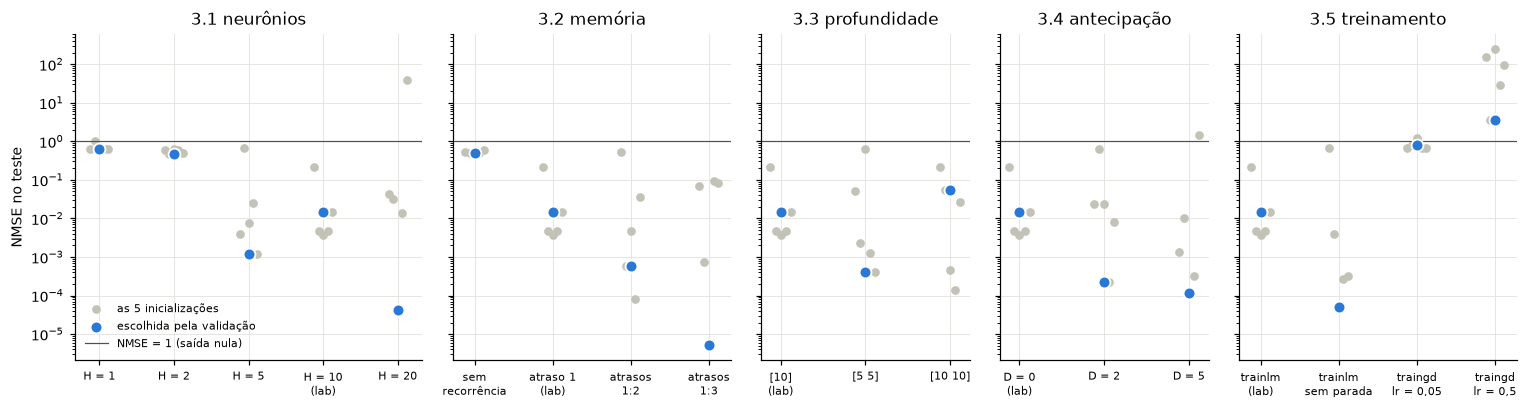

In [11]:
ROTULO = {'sem recorrência': 'sem\nrecorrência', 'atraso 1 (lab)': 'atraso 1\n(lab)', 'atrasos 1:2': 'atrasos\n1:2',
          'atrasos 1:3': 'atrasos\n1:3', 'trainlm (lab)': 'trainlm\n(lab)', 'trainlm sem parada antecipada': 'trainlm\nsem parada',
          'traingd, lr = 0,05': 'traingd\nlr = 0,05', 'traingd, lr = 0,5': 'traingd\nlr = 0,5'}
fig, ax = plt.subplots(1, 5, figsize=(14, 3.8), sharey=True, gridspec_kw=dict(width_ratios=[5, 4, 3, 3, 4]))
for a, (grupo, cfgs) in zip(ax, EXPERIMENTOS.items()):
    for i, nome in enumerate(cfgs):
        redes = redes_exp[nome]
        te = np.array([nmse(r(x_te), r_te) for r in redes])
        a.scatter(np.full(len(te), i) + np.linspace(-0.12, 0.12, len(te)), te, s=22, color='#c3c2b7', zorder=2,
                  label='as 5 inicializações' if i == 0 else None)
        a.scatter(i, nmse(melhor(redes)(x_te), r_te), s=60, color=COR[0], edgecolor='white', lw=1.2, zorder=3,
                  label='escolhida pela validação' if i == 0 else None)
    a.axhline(1, color='#52514e', lw=0.8, label='NMSE = 1 (saída nula)' if a is ax[0] else None)
    a.set_xticks(range(len(cfgs)), [ROTULO.get(c, c.replace(' (lab)', '\n(lab)')) for c in cfgs], fontsize=7.5)
    a.set_title(grupo)
ax[0].set_yscale('log')
ax[0].set_ylabel('NMSE no teste')
ax[0].legend(loc='lower left', fontsize=7.5)
plt.tight_layout()

Previsões no conjunto de teste da rede escolhida em algumas configurações:

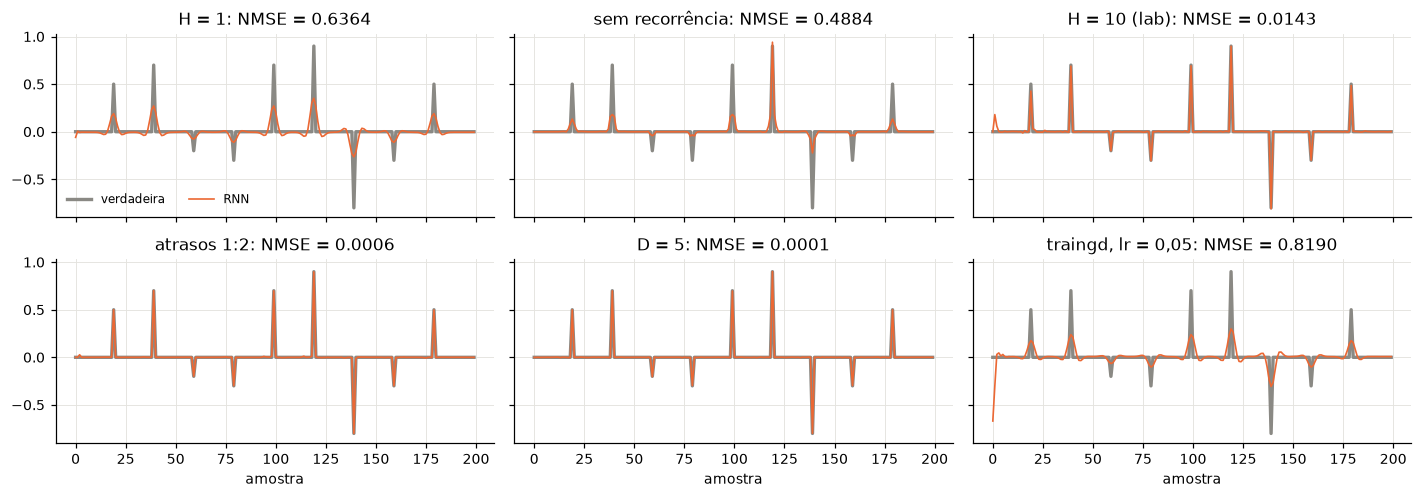

In [12]:
mostrar = ['H = 1', 'sem recorrência', 'H = 10 (lab)', 'atrasos 1:2', 'D = 5', 'traingd, lr = 0,05']
fig, ax = plt.subplots(2, 3, figsize=(13, 4.6), sharex=True, sharey=True)
for a, nome in zip(ax.flat, mostrar):
    p = melhor(redes_exp[nome])(x_te)
    a.plot(r_te, color=VERD, lw=2.2, label='verdadeira')
    a.plot(p, color=COR[1], lw=1.1, label='RNN')
    a.set_title(f'{nome}: NMSE = {nmse(p, r_te):.4f}')
ax[0, 0].legend(loc='lower left', ncol=2, fontsize=8)
for a in ax[1]:
    a.set_xlabel('amostra')
plt.tight_layout()

**3.1 Neurônios.** Com 1 ou 2 neurônios, nenhuma inicialização converge (NMSE de 0,46 a 0,64). A rede só produz spikes achatados (no painel *H = 1*, os picos saem com cerca de 30 % da amplitude), porque não tem graus de liberdade para manter o pico e cancelar os lobos laterais ao mesmo tempo. A partir de 5 neurônios o problema está resolvido: 4 de 5 inicializações convergem, e a rede escolhida tem NMSE entre $10^{-3}$ e $10^{-5}$.

Mais neurônios baixam o melhor erro (H = 20: $4\times10^{-5}$), mas não a mediana, e custam mais. O número de parâmetros cresce com $H^2$ (131 com H = 10, 461 com H = 20), e cada passo do LM resolve um sistema $P\times P$.

**3.2 Memória.** Sem realimentação, a rede é estática: $\hat r(t)$ depende só de $x(t)$, e uma amostra isolada não diz se é o pico de um evento fraco ou o flanco de um evento forte. Só o spike mais forte sai razoável, os outros saem muito atenuados (NMSE ≈ 0,49, nenhuma inicialização converge).

Com mais atrasos ($\mathbf R_1\mathbf h(t-1) + \mathbf R_2\mathbf h(t-2) + \dots$), a rede acessa diretamente estados mais antigos. As 5 inicializações convergem, e o erro da rede escolhida cai para $6\times10^{-4}$ (atrasos 1:2) e $5\times10^{-6}$ (atrasos 1:3). O custo é 1,8 a 2,5 vezes mais parâmetros e 3 a 4 vezes mais tempo de treino. Nesse grupo a mediana não melhora (0,005 e 0,07): o ajuste ao treino é muito bom em todas as inicializações, mas a generalização para o teste varia mais entre elas.

**3.3 Profundidade.** Duas camadas não trouxeram ganho sistemático. A `[5 5]`, com menos parâmetros que a `[10]` (96 contra 131), chegou a $4\times10^{-4}$. A `[10 10]` convergiu em todas as inicializações, mas a rede escolhida generalizou pior (0,053). Neste problema a profundidade não é o gargalo: uma camada com 5 a 10 neurônios já tem capacidade de sobra.

**3.4 Antecipação.** Deixar a rede olhar 2 ou 5 amostras à frente reduz o erro da rede escolhida em cerca de 2 ordens de grandeza (de 0,0143 para $2\times10^{-4}$ e $1\times10^{-4}$), sem nenhum parâmetro a mais. Com $D > 0$, a rede também vê o flanco de **descida** antes de decidir se aquele instante era o pico, em vez de deduzir isso só pela forma do flanco de subida. O custo é uma latência de $D$ amostras, irrelevante em processamento sísmico, que é feito depois da aquisição.

### 3.5 Algoritmo de treino

Curvas de aprendizado da rede escolhida em cada variante de treino:

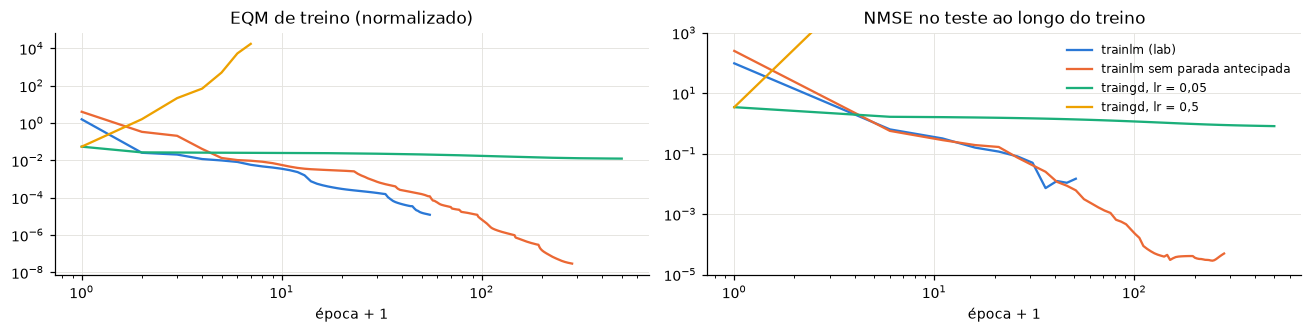

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.1))
for i, nome in enumerate(EXPERIMENTOS['3.5 treinamento']):  # a rede escolhida de cada variante
    rede = melhor(redes_exp[nome])
    h = np.array(rede.hist['treino'])
    ax[0].loglog(np.arange(1, len(h) + 1), h, color=COR[i], lw=1.5, label=nome)
    nm_ep = [nmse(rede(x_te, th), r_te) for th in rede.hist['th'][::5]]
    ax[1].loglog(np.arange(1, len(h) + 1, 5), nm_ep, color=COR[i], lw=1.5, label=nome)
ax[0].set(title='EQM de treino (normalizado)', xlabel='época + 1')
ax[1].set(title='NMSE no teste ao longo do treino', xlabel='época + 1', ylim=(1e-5, 1e3))
ax[1].legend(fontsize=8)
plt.tight_layout()

* **Parada antecipada.** Sem ela (100 % das amostras no treino, 500 épocas), o NMSE de teste da rede escolhida cai de 0,0143 para $5\times10^{-5}$, e a mediana de 0,0048 para $3\times10^{-4}$. Os dados não têm ruído e são 2000 amostras para 131 parâmetros, então não há sobreajuste a evitar. Com `max_fail = 6`, a validação, que é ruidosa, interrompe o LM enquanto o erro de teste ainda está caindo (curva laranja, à direita). O preço é o tempo: as 500 épocas custam cerca de 8 a 10 vezes mais que o treino com parada antecipada (coluna de tempo da tabela).
* **`traingd` com lr = 0,05,** o valor que o lab define e que não tem efeito no `trainlm`. Em 500 épocas, o EQM de treino quase não cai e nenhuma inicialização converge: a rede escolhida tem NMSE de teste 0,82. O gradiente descendente com passo fixo é muito lento neste problema mal condicionado. O LM, que usa a curvatura $\mathbf J^\top\mathbf J$, chega a $10^{-4}$ em cerca de 50 épocas.
* **`traingd` com lr = 0,5:** diverge já nas primeiras épocas (o EQM de treino passa de $10^{-1}$ para $10^{4}$). A rede devolvida é a da época 0, a de menor erro de validação, ou seja, a rede sem treino.

### 3.6 Sensibilidade à inicialização: explosão do gradiente

Algumas inicializações param logo no início, por "mu máximo": nenhum passo, nem com $\mu = 10^{10}$, reduz o erro. A tabela lista esses casos entre todas as redes treinadas até aqui, com o raio espectral $\rho(\mathbf R)$ da matriz de realimentação antes e depois do treino:

In [14]:
todas = [('deconvolução: ' + nome, s, r, x_tr) for nome, redes in redes_exp.items() if redes is not lab for s, r in zip(SEMENTES, redes)]
todas += [('deconvolução: lab', s, r, x_tr) for s, r in zip(SEMENTES, lab)]
todas += [(f'convolução (tarefa 1), D = {D}', s, r, r_tr) for D, redes in conv.items() for s, r in zip(SEMENTES, redes)]
falhas = [(n, s, r, e) for n, s, r, e in todas if r.motivo == 'mu máximo']
display(pd.DataFrame([{'experimento': n, 'semente': s, 'épocas': r.epocas, 'EQM treino inicial → final': f"{r.hist['treino'][0]:.3f} → {r.hist['treino'][-1]:.3f}",
                       'ρ(R) inicial': f'{r.rho0:.2f}', 'ρ(R) final': f"{r.raio_espectral(r.hist['th'][-1]):.2f}"}
                      for n, s, r, e in falhas]))
print(f'{len(falhas)} de {len(todas)} treinos pararam por "mu máximo"')

,experimento,semente,épocas,EQM treino inicial → final,ρ(R) inicial,ρ(R) final
0,deconvolução: H = 20,4,2,4.716 → 0.707,0.85,2.14
1,deconvolução: D = 5,4,36,1.573 → 0.023,0.76,1.97
2,deconvolução: trainlm sem parada antecipada,0,14,2.529 → 0.012,0.78,4.83
3,"convolução (tarefa 1), D = 0",0,2,2.552 → 0.496,0.78,2.10
4,"convolução (tarefa 1), D = 0",4,1,1.606 → 1.053,0.76,4.15
5,"convolução (tarefa 1), D = 10",2,3,4.012 → 0.353,0.71,6.28


6 de 90 treinos pararam por "mu máximo"


Para ver o que acontece, a figura compara o tamanho das derivadas $\max_p |\partial\hat y(t)/\partial\theta_p|$ ao longo da sequência de treino. Uma curva é a de uma rede que falhou, no último passo do treino; a outra é a da rede do lab já treinada:

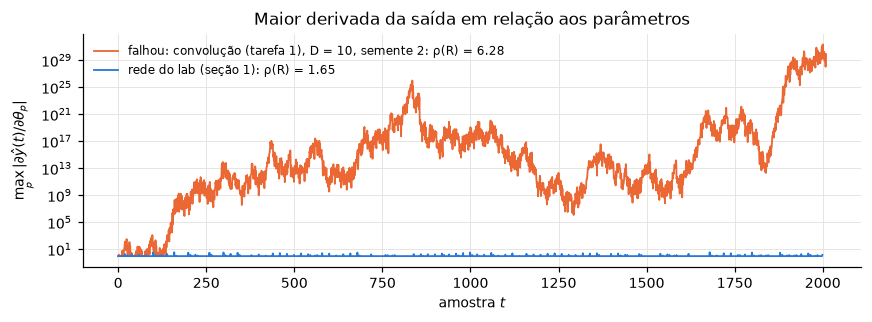

In [15]:
curvas_J = [(base, x_tr, base.th, 'rede do lab (seção 1)', COR[0])]
if falhas:
    n_f, s_f, r_f, e_f = max(falhas, key=lambda f: f[2].raio_espectral(f[2].hist['th'][-1]))
    curvas_J.insert(0, (r_f, e_f, r_f.hist['th'][-1], f'falhou: {n_f}, semente {s_f}', COR[1]))
fig, ax = plt.subplots(figsize=(8, 3))
for rede, ent, th, nome, cor in curvas_J:
    with np.errstate(all='ignore'):
        _, J = rede.propaga(th, np.concatenate([rede.nx(ent), np.zeros(rede.atraso_saida)]), jac=True)
    ax.semilogy(np.abs(J).max(1), color=cor, lw=1.2, label=f'{nome}: ρ(R) = {rede.raio_espectral(th):.2f}')
ax.set(title='Maior derivada da saída em relação aos parâmetros', xlabel='amostra $t$', ylabel=r'$\max_p |\partial \hat y(t) / \partial \theta_p|$')
ax.legend(fontsize=8)
plt.tight_layout()

Nos 6 casos, o raio espectral da realimentação sobe de 0,7–0,85 para 2–6, e o treino para porque nenhum passo reduz o erro. No caso da figura, isso acontece em 3 épocas: um passo de Gauss-Newton (μ pequeno) reduz o erro de treino, mas deixa a dinâmica da rede **caótica**.

A sensibilidade $\partial\mathbf h(t)/\partial\boldsymbol\theta$ é propagada pelo produto das matrizes $\mathrm{diag}(1-\mathbf h^2)\,\mathbf R$ ao longo da sequência. Com dinâmica caótica, ela cresce exponencialmente e chega a ~$10^{29}$ na figura, contra valores menores que 10 na rede do lab. Com um jacobiano desse tamanho, o modelo linear do LM só vale numa vizinhança minúscula, e nem $\mu = 10^{10}$ deixa o passo pequeno o bastante. É o problema da **explosão do gradiente** das RNNs simples (Bengio et al., 1994; Pascanu et al., 2013).

* $\rho(\mathbf R) > 1$ não basta para a explosão. A rede do lab tem $\rho = 1{,}65$ e derivadas limitadas, porque a saturação da tanh (o fator $1 - \mathbf h^2$) contrai a dinâmica. O que importa é o produto ao longo da trajetória.
* Os remédios usuais são limitar a norma do gradiente ou do passo (*gradient clipping*), regularizar os pesos recorrentes, começar com passos menores ou, simplesmente, treinar a partir de várias inicializações. É o que se faz aqui, e o que se faz no MATLAB ao rodar `train` de novo.

### 3.7 Generalização fora da distribuição de treino

O teste do lab tem a mesma estrutura do treino: spikes isolados a cada 20 amostras, **na mesma fase** (amostras 19, 39, 59, ...), e a mesma wavelet. Os testes abaixo saem dessa distribuição:

* **lab deslocado:** o mesmo teste deslocado de $k = 0, \dots, 19$ amostras; a tabela mostra o pior caso;
* **espaçamento irregular:** 2000 amostras com spikes separados por 8 a 32 amostras, então as wavelets vizinhas às vezes se sobrepõem;
* **Ricker de 1,2 Hz:** outra wavelet, para checar o quanto a deconvolução é realmente "cega";
* **ruído:** o teste do lab com ruído gaussiano branco, SNR = 20 dB.

In [16]:
def deslocado(k):
    r = np.roll(np.pad(r_te, (0, 20)), k)
    return sismograma(r, wav, PICO), r


r_irr = np.zeros(2000)
ri, t = np.random.default_rng(5), 10
while (t := t + 8 + ri.integers(0, 25)) < 1990:
    r_irr[t] = ri.uniform(-1, 1)
x_irr = sismograma(r_irr, wav, PICO)
w12 = ricker(1000, 1.2, DT)
x_12 = sismograma(r_te, w12, int(np.argmax(w12)))
x_ruido = x_te + np.random.default_rng(6).normal(0, np.sqrt(np.mean(x_te**2)) / 10, len(x_te))   # 20 dB


def generalizacao(rede):
    return {'teste do lab': nmse(rede(x_te), r_te),
            'lab deslocado (pior k)': max(nmse(rede(x), r) for x, r in map(deslocado, range(20))),
            'espaçamento irregular': nmse(rede(x_irr), r_irr), 'Ricker 1,2 Hz': nmse(rede(x_12), r_te),
            'ruído 20 dB': nmse(rede(x_ruido), r_te)}


comparar = ['H = 10 (lab)', 'H = 20', 'atrasos 1:2', 'atrasos 1:3', '[10 10]', 'D = 2', 'D = 5', 'trainlm sem parada antecipada']
tab = pd.DataFrame({nome: generalizacao(melhor(redes_exp[nome])) for nome in comparar}).T
display(tab.map(fmt))

,teste do lab,lab deslocado (pior k),espaçamento irregular,"Ricker 1,2 Hz",ruído 20 dB
H = 10 (lab),0.0143,0.0155,0.0458,0.6692,0.0800
H = 20,4.1e-05,1.0e-04,0.0095,0.4724,0.3222
atrasos 1:2,5.7e-04,0.0307,0.1091,1.4710,0.1877
atrasos 1:3,5.1e-06,1.4e-05,0.0355,0.5907,0.2122
[10 10],0.0532,0.0532,0.0551,0.7778,0.3789
D = 2,2.3e-04,2.5e-04,0.0573,0.7308,0.1362
D = 5,1.1e-04,1.2e-04,0.0448,3.6492,0.2319
trainlm sem parada antecipada,5.1e-05,5.3e-05,0.0567,0.2834,0.1014


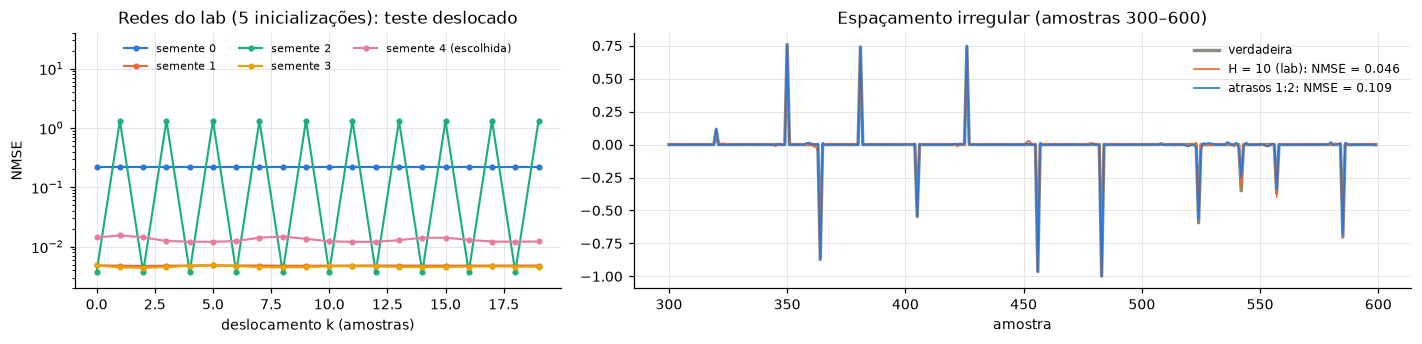

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[1, 1.6]))
for s, rede in zip(SEMENTES, lab):
    curva = [nmse(rede(x), r) for x, r in map(deslocado, range(20))]
    ax[0].semilogy(range(20), curva, color=COR[s], lw=1.4, marker='o', ms=3,
                   label=f'semente {s}' + (' (escolhida)' if rede is base else ''))
ax[0].set(title='Redes do lab (5 inicializações): teste deslocado', xlabel='deslocamento k (amostras)', ylabel='NMSE', ylim=(2e-3, 40))
ax[0].legend(fontsize=7.5, ncol=3, loc='upper center')
s = slice(300, 600)
ax[1].plot(np.arange(2000)[s], r_irr[s], color=VERD, lw=2.2, label='verdadeira')
for nome, cor in [('H = 10 (lab)', COR[1]), ('atrasos 1:2', COR[0])]:
    p = melhor(redes_exp[nome])(x_irr)
    ax[1].plot(np.arange(2000)[s], p[s], color=cor, lw=1.1, label=f'{nome}: NMSE = {nmse(p, r_irr):.3f}')
ax[1].set(title='Espaçamento irregular (amostras 300–600)', xlabel='amostra')
ax[1].legend(fontsize=8, loc='upper right')
plt.tight_layout()

* **Deslocamento.** As redes escolhidas são, em geral, invariantes ao deslocamento: o pior caso fica igual ao teste original, como se espera de um filtro recorrente. A exceção é a de atrasos 1:2, que vai de $6\times10^{-4}$ a 0,031. O caso mais instrutivo, porém, está entre as 5 inicializações do lab (figura à esquerda). A semente 2, que tem o **melhor** NMSE no teste original (0,0038), erra completamente (NMSE ≈ 1,3) quando o teste é deslocado de um número **ímpar** de amostras. A explicação vem logo abaixo.
* **Espaçamento irregular.** O erro aumenta em todas as redes e vai para 0,01–0,11, inclusive nas que tinham $10^{-4}$ a $10^{-6}$ no teste do lab. Spikes separados por 8 a 12 amostras produzem wavelets sobrepostas, situação que nunca aparece no treino. Mesmo assim, posições e sinais dos spikes continuam corretos (figura à direita).
* **Outra wavelet.** Com a Ricker de 1,2 Hz, todas as redes falham (NMSE de 0,28 a 3,6). A deconvolução é "cega" só no sentido de que a wavelet não é informada de forma explícita: o filtro inverso de **uma** wavelet fica gravado nos pesos. Para dados reais, com wavelet desconhecida e variável, o treino precisaria incluir várias wavelets.
* **Ruído.** Com SNR = 20 dB, o NMSE sobe para 0,08–0,38. A deconvolução é mal condicionada, porque o filtro inverso amplifica as frequências em que a wavelet tem pouca energia, e as redes treinadas sem ruído herdam essa amplificação. As que melhor se ajustaram ao teste sem ruído (H = 20, `[10 10]`, D = 5) estão entre as mais sensíveis; a rede do lab foi a mais robusta (0,08).

Em resumo, um NMSE baixo no teste do lab, que vem da mesma distribuição do treino, superestima a qualidade da deconvolução. Para avaliá-la de fato, é preciso testar fora dessa distribuição. Para melhorá-la, é preciso treinar com refletividades, wavelets e níveis de ruído variados.

**Por que a semente 2 depende da paridade?** A tabela mostra a dinâmica livre de cada rede do lab, com o sismograma nulo na entrada:

In [18]:
# dinâmica livre de cada rede do lab: entrada nula (sismograma = 0) por 300 amostras
linhas = []
for s, rede in zip(SEMENTES, lab):
    W, R, b = rede._get(rede.th, 'W0')[:, 0], rede._get(rede.th, 'R0_1'), rede._get(rede.th, 'b0')
    ev = np.linalg.eigvals(R)
    reais = ev[np.abs(ev.imag) < 1e-9].real
    u0, h, H = rede.nx(np.zeros(1))[0], np.zeros(len(b)), []
    for _ in range(300):
        h = np.tanh(W * u0 + R @ h + b)
        H.append(h)
    H = np.array(H[-50:])
    linhas.append({'semente': s, 'NMSE teste do lab': fmt(nmse(rede(x_te), r_te)),
                   'pior NMSE deslocado': fmt(max(nmse(rede(x), r) for x, r in map(deslocado, range(20)))),
                   'autovalor real mais negativo de R': f'{reais.min():.2f}' if len(reais) else '—',
                   'max |h(t) − h(t−1)|': f'{np.abs(np.diff(H, axis=0)).max():.3f}',
                   'max |h(t) − h(t−2)|': f'{np.abs(H[2:] - H[:-2]).max():.3f}'})
display(pd.DataFrame(linhas).set_index('semente'))

,NMSE teste do lab,pior NMSE deslocado,autovalor real mais negativo de R,max |h(t) − h(t−1)|,max |h(t) − h(t−2)|
semente,,,,,
0,0.2166,0.2175,-0.90,0.000,0.000
1,0.0048,0.0048,-1.27,0.000,0.000
2,0.0038,1.3265,-1.99,1.145,0.000
3,0.0048,0.0049,—,0.000,0.000
4,0.0143,0.0155,—,0.000,0.000


A matriz de realimentação da semente 2 tem um autovalor real em −1,99. Com entrada nula, o estado dessa rede não converge para um ponto fixo: ele **oscila com período 2** ($\mathbf h(t) = \mathbf h(t-2) \neq \mathbf h(t-1)$). A rede usa essa oscilação como um relógio interno de paridade. No treino, todos os spikes caem em instantes ímpares (amostras 19, 39, 59, ...), e a rede aprendeu a deconvolver só nessa fase do relógio. As outras sementes convergem para um ponto fixo e não têm esse problema. A semente 1 também tem um autovalor real menor que −1 (−1,27), mas a saturação da tanh leva seu estado a um ponto fixo: o que decide é a dinâmica não linear, não o autovalor isolado.

O teste do lab, com a mesma fase do treino, não tem como detectar isso. É um exemplo de rede que aprende uma regularidade acidental dos dados (o espaçamento fixo de 20 amostras) em vez do fenômeno físico.

## 4. Tarefa (3): LSTM, a calculadora binária (`RNN_binary_lstm.m`)

**O problema.** Somar dois inteiros de 8 bits, $a \in [1, 128]$ e $b \in [1, 127]$, lendo um bit de cada por vez, **do menos para o mais significativo**. A cada passo a entrada é $(a_t, b_t)$ e o alvo é o bit $c_t$ da soma. Para acertar, a rede precisa lembrar o **"vai-um"** do passo anterior.

**A célula LSTM** (equações (1)–(7) dos comentários do `.m`):

$$\begin{aligned}
\mathbf i_t &= \sigma(\mathbf x_t\mathbf X_i + \mathbf h_{t-1}\mathbf H_i + b_i) &&\text{porta de entrada}\\
\mathbf f_t &= \sigma(\mathbf x_t\mathbf X_f + \mathbf h_{t-1}\mathbf H_f + b_f) &&\text{porta de esquecimento}\\
\mathbf o_t &= \sigma(\mathbf x_t\mathbf X_o + \mathbf h_{t-1}\mathbf H_o + b_o) &&\text{porta de saída}\\
\mathbf g_t &= \tanh(\mathbf x_t\mathbf X_g + \mathbf h_{t-1}\mathbf H_g + b_g) &&\text{candidato}\\
\mathbf C_t &= \mathbf C_{t-1}\odot\mathbf f_t + \mathbf g_t\odot\mathbf i_t &&\text{estado da célula}\\
\mathbf h_t &= \tanh(\mathbf C_t)\odot\mathbf o_t, \qquad \hat c_t = \sigma(\mathbf h_t\,\mathbf w_{out})
\end{aligned}$$

Ao contrário da RNN do lab, aqui a memória fica no estado $\mathbf C_t$, que é atualizado de forma **aditiva** e controlado por portas sigmoides: $\mathbf f_t$ decide o que manter, $\mathbf i_t$ o que escrever e $\mathbf o_t$ o que expor.

**O treino do `.m`:** 32 unidades, pesos iniciais $U(-1, 1)$, uma soma sorteada por iteração (treino *online*), 9000 iterações, $\alpha = 0{,}1$. O erro de saída é `y - pred`, sem a derivada da sigmoide, que é o gradiente da entropia cruzada.

### 4.1 Tradução fiel do `RNN_binary_lstm.m`

In [19]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
BITS = 8


def bits(n, nb=BITS):
    # bits de n, do menos para o mais significativo (a ordem em que a rede lê)
    return (np.asarray(n)[..., None] >> np.arange(nb)) & 1


def para_int(bs):
    return (np.asarray(bs) * (1 << np.arange(np.shape(bs)[-1]))).sum(-1)


def sorteia_soma(rng):
    a, b = rng.integers(1, 129), rng.integers(1, 128)               # randi(round(255/2)), randi(floor(255/2))
    return a, b, np.stack([bits(a), bits(b)], -1)[None].astype(float), bits(a + b).astype(float)


def lstm_forward(p, X):
    # X: (N, T, 2) -> previsões (N, T) e estados de cada passo (lotes de N somas de uma vez)
    N, T, _ = X.shape
    h, C = np.zeros((N, p['Hi'].shape[0])), np.zeros((N, p['Hi'].shape[0]))
    st = {k: [] for k in 'ifogCH'}
    st['H'].append(h); st['C'].append(C)
    pred = []
    for t in range(T):
        x = X[:, t]
        i = sigmoid(x @ p['Xi'] + h @ p['Hi'] + p['bi'])               # (1)
        f = sigmoid(x @ p['Xf'] + h @ p['Hf'] + p['bf'])               # (2)
        o = sigmoid(x @ p['Xo'] + h @ p['Ho'] + p['bo'])               # (3)
        g = np.tanh(x @ p['Xg'] + h @ p['Hg'] + p['bg'])               # (4)
        C = C * f + g * i                                              # (5)
        h = np.tanh(C) * o                                             # (6)
        for k, v in zip('ifogCH', (i, f, o, g, C, h)):
            st[k].append(v)
        pred.append(sigmoid(h @ p['out'])[:, 0])                       # (7)
    return np.stack(pred, 1), st


def lstm_treinar(versao='lab', iters=9000, alpha=0.1, hd=32, semente=0, mostra=0):
    # versao='lab': igual ao .m.  versao='bptt': retropropagação completa no tempo, com a derivada correta de tanh(C).
    rng = np.random.default_rng(semente)
    U = lambda *s: 2 * rng.random(s) - 1
    p = {}
    for g in 'ifog':                                                   # mesma ordem de sorteio do .m
        p['X' + g], p['H' + g], p['b' + g] = U(2, hd), U(hd, hd), U(1)  # os vieses começam escalares
    p['out'] = U(hd, 1)
    erros = []
    for j in range(1, iters + 1):
        a_int, b_int, X, y = sorteia_soma(rng)
        pred, st = lstm_forward(p, X)
        delta = y - pred[0]                                            # output_deltas
        upd = {k: np.zeros_like(v) for k, v in p.items()}
        dh_fut, dC_fut = np.zeros((1, hd)), np.zeros((1, hd))          # future_H_diff (no .m fica sempre zero)
        for t in reversed(range(BITS)):
            x = X[:, t]
            I, F, O, G = (st[k][t] for k in 'ifog')
            C, C_ant, H, H_ant = st['C'][t + 1], st['C'][t], st['H'][t + 1], st['H'][t]
            upd['out'] += H.T * delta[t]                               # out_para_diff
            dH = delta[t] * p['out'].T                                 # H_t_diff
            if versao == 'lab':
                dO = dH * np.tanh(C) * O * (1 - O)
                dC = dH * O * (1 - C**2)                               # tan_h_output_to_derivative(C_t)
            else:
                dH = dH + dh_fut
                dO = dH * np.tanh(C) * O * (1 - O)
                dC = dH * O * (1 - np.tanh(C)**2) + dC_fut
            dF = dC * C_ant * F * (1 - F)
            dI = dC * G * I * (1 - I)
            dG = dC * I * (1 - G**2)
            for g, d in zip('ifog', (dI, dF, dO, dG)):
                upd['X' + g] += x.T @ d
                upd['H' + g] += H_ant.T @ d
                upd['b' + g] = upd['b' + g] + d[0]                     # escalar + vetor (1 x hd): o viés vira vetor
            if versao != 'lab':
                dh_fut = dI @ p['Hi'].T + dF @ p['Hf'].T + dO @ p['Ho'].T + dG @ p['Hg'].T
                dC_fut = dC * F
        for k in p:
            p[k] = p[k] + alpha * upd[k]
        if j % 10 == 0:
            erros.append(np.abs(delta).sum())                          # allErr
        if mostra and j % mostra == 0:
            d = para_int(np.round(pred[0]).astype(int))
            print(f'iteração {j:5d} | erro {np.abs(delta).sum():.4f} | previsto {np.binary_repr(d, 8)} | '
                  f'verdadeiro {np.binary_repr(a_int + b_int, 8)} | {a_int:3d} + {b_int:3d} = {d}')
    return p, np.array(erros)


p_lab, err_lab = lstm_treinar('lab', semente=0, mostra=1000)

iteração  1000 | erro 0.0399 | previsto 01100000 | verdadeiro 01100000 |  27 +  69 = 96


iteração  2000 | erro 0.0168 | previsto 01100010 | verdadeiro 01100010 |  16 +  82 = 98


iteração  3000 | erro 0.0059 | previsto 00100000 | verdadeiro 00100000 |  22 +  10 = 32


iteração  4000 | erro 3.9814 | previsto 10000101 | verdadeiro 01011101 |  75 +  18 = 133


iteração  5000 | erro 1.7776 | previsto 01101100 | verdadeiro 01011100 |  54 +  38 = 108


iteração  6000 | erro 0.1366 | previsto 01010101 | verdadeiro 01010101 |   5 +  80 = 85


iteração  7000 | erro 0.1847 | previsto 01100001 | verdadeiro 01100001 |   4 +  93 = 97


iteração  8000 | erro 0.0805 | previsto 10011110 | verdadeiro 10011110 |  58 + 100 = 158


iteração  9000 | erro 0.1359 | previsto 10101011 | verdadeiro 10101011 |  61 + 110 = 171


Em vez de olhar só a soma sorteada a cada 1000 iterações, a função abaixo avalia a rede treinada em **todas** as $128 \times 127 = 16\,256$ somas possíveis. Ela também mede a generalização para **16 bits**: as mesmas células, sem retreino, aplicadas a 10 000 somas de números de até 15 bits.

In [20]:
def avalia(forward, p, nbits=BITS, n=None, semente=0):
    if n is None:                                                      # todas as somas do treino
        A, B = (v.ravel() for v in np.meshgrid(np.arange(1, 129), np.arange(1, 128), indexing='ij'))
    else:
        rr = np.random.default_rng(semente)
        A, B = rr.integers(1, 2 ** (nbits - 1), n), rr.integers(1, 2 ** (nbits - 1), n)
    X = np.stack([bits(A, nbits), bits(B, nbits)], -1).astype(float)
    pred, st = forward(p, X)
    certo = np.round(pred).astype(int) == bits(A + B, nbits)
    return {'bits certos (%)': 100 * certo.mean(), 'somas exatas (%)': 100 * certo.all(1).mean()}, (A, B, pred, st)


print('8 bits: ', {k: round(v, 2) for k, v in avalia(lstm_forward, p_lab)[0].items()})
print('16 bits:', {k: round(v, 2) for k, v in avalia(lstm_forward, p_lab, 16, n=10_000)[0].items()})

8 bits:  {'bits certos (%)': np.float64(99.68), 'somas exatas (%)': np.float64(98.26)}


16 bits: {'bits certos (%)': np.float64(97.99), 'somas exatas (%)': np.float64(83.97)}


### 4.2 Revisão do código e versão corrigida

Comparado à LSTM de livro-texto, o `RNN_binary_lstm.m` tem três diferenças:

1. **Retropropagação truncada em um passo.** As linhas com `future_H_diff` e `C_t_1_diff` estão comentadas, então o erro do passo $t$ não volta para os passos anteriores. Os pesos recorrentes $\mathbf H_*$ aprendem a *usar* $\mathbf h_{t-1}$, mas nada ensina a rede a *guardar* o vai-um em $\mathbf h_{t-1}$ ou $\mathbf C_{t-1}$.
2. **Derivada errada.** `tan_h_output_to_derivative(C_t)` calcula $1 - \mathbf C_t^2$, mas a derivada de $\tanh(\mathbf C_t)$ é $1 - \tanh^2(\mathbf C_t)$. As duas expressões só coincidem para $\mathbf C_t \approx 0$.
3. Os vieses começam como escalares compartilhados pelas 32 unidades e viram vetores na primeira atualização, por *broadcasting*. Isso é inofensivo.

A versão `'bptt'` corrige 1 e 2: retropropagação completa no tempo (BPTT) com a derivada certa. Para comparar, entram também duas **RNNs sem portas**, $\mathbf h_t = f(\mathbf x_t\mathbf X + \mathbf h_{t-1}\mathbf H + \mathbf b)$, com o mesmo tamanho, a mesma inicialização, o mesmo $\alpha$ e BPTT: uma com $f$ = sigmoide e outra com $f$ = tanh, a ativação da RNN do lab. Cada modelo é treinado a partir de 5 sementes.

In [21]:
def rnn_forward(p, X, f=None):
    f = f or {'sigmoide': sigmoid, 'tanh': np.tanh}[p['ativ']]
    h = np.zeros((X.shape[0], p['H'].shape[0]))
    Hs, pred = [h], []
    for t in range(X.shape[1]):
        h = f(X[:, t] @ p['X'] + h @ p['H'] + p['b'])
        Hs.append(h)
        pred.append(sigmoid(h @ p['out'])[:, 0])
    return np.stack(pred, 1), {'H': Hs}


def rnn_treinar(ativ='sigmoide', iters=9000, alpha=0.1, hd=32, semente=0):
    rng = np.random.default_rng(semente)
    U = lambda *s: 2 * rng.random(s) - 1
    p = {'X': U(2, hd), 'H': U(hd, hd), 'b': U(hd), 'out': U(hd, 1)}
    df = (lambda h: h * (1 - h)) if ativ == 'sigmoide' else (lambda h: 1 - h**2)
    erros, normas = [], []
    for j in range(1, iters + 1):
        _, _, X, y = sorteia_soma(rng)
        pred, st = rnn_forward({**p, 'ativ': ativ}, X)
        delta = y - pred[0]
        upd = {k: np.zeros_like(v) for k, v in p.items()}
        dh_fut = np.zeros((1, hd))
        for t in reversed(range(BITS)):
            H, H_ant = st['H'][t + 1], st['H'][t]
            upd['out'] += H.T * delta[t]
            dA = (delta[t] * p['out'].T + dh_fut) * df(H)
            upd['X'] += X[:, t].T @ dA
            upd['H'] += H_ant.T @ dA
            upd['b'] += dA[0]
            dh_fut = dA @ p['H'].T
        normas.append(np.sqrt(sum((u**2).sum() for u in upd.values())))
        for k in p:
            p[k] = p[k] + alpha * upd[k]
        if j % 10 == 0:
            erros.append(np.abs(delta).sum())
    p['ativ'] = ativ
    return p, np.array(erros), np.array(normas)


MODELOS = {'LSTM do lab': ('lstm', 'lab'), 'LSTM corrigida (BPTT)': ('lstm', 'bptt'),
           'RNN sem portas, sigmoide': ('rnn', 'sigmoide'), 'RNN sem portas, tanh': ('rnn', 'tanh')}


def _treina_bin(tarefa):
    nome, s = tarefa
    tipo, var = MODELOS[nome]
    if tipo == 'lstm':
        p, e = lstm_treinar(var, semente=s)
        return p, e, None
    return rnn_treinar(var, semente=s)


t0 = time.perf_counter()
tarefas = [(nome, s) for nome in MODELOS for s in SEMENTES]
if N_PROC > 1:
    with ProcessPoolExecutor(N_PROC, mp_context=mp.get_context('fork')) as ex:
        saidas = list(ex.map(_treina_bin, tarefas))
else:
    saidas = [_treina_bin(t) for t in tarefas]
bin_res = {}
for (nome, s), saida in zip(tarefas, saidas):
    bin_res.setdefault(nome, []).append(saida)
print(f'{len(tarefas)} redes treinadas em {time.perf_counter() - t0:.0f} s')

linhas = []
for nome, res in bin_res.items():
    fwd = lstm_forward if MODELOS[nome][0] == 'lstm' else rnn_forward
    a8 = [avalia(fwd, p)[0] for p, _, _ in res]
    a16 = [avalia(fwd, p, 16, n=10_000)[0] for p, _, _ in res]
    faixa = lambda v: f'{np.mean(v):.1f} ({np.min(v):.1f}–{np.max(v):.1f})'
    linhas.append({'modelo': nome, '8 bits: bits certos (%)': faixa([a['bits certos (%)'] for a in a8]),
                   '8 bits: somas exatas (%)': faixa([a['somas exatas (%)'] for a in a8]),
                   '16 bits: somas exatas (%)': faixa([a['somas exatas (%)'] for a in a16]),
                   'erro final (média das últimas 500 iterações)': f"{np.mean([e[-50:].mean() for _, e, _ in res]):.3f}"})
print('média (mínimo–máximo) entre as 5 sementes')
display(pd.DataFrame(linhas).set_index('modelo'))

20 redes treinadas em 17 s


média (mínimo–máximo) entre as 5 sementes


,8 bits: bits certos (%),8 bits: somas exatas (%),16 bits: somas exatas (%),erro final (média das últimas 500 iterações)
modelo,,,,
LSTM do lab,99.1 (96.0–100.0),95.4 (81.7–100.0),84.5 (62.5–98.8),0.202
LSTM corrigida (BPTT),100.0 (100.0–100.0),100.0 (100.0–100.0),100.0 (100.0–100.0),0.003
"RNN sem portas, sigmoide",100.0 (100.0–100.0),100.0 (100.0–100.0),100.0 (100.0–100.0),0.009
"RNN sem portas, tanh",57.6 (56.3–59.3),0.6 (0.0–1.7),0.0 (0.0–0.0),3.467


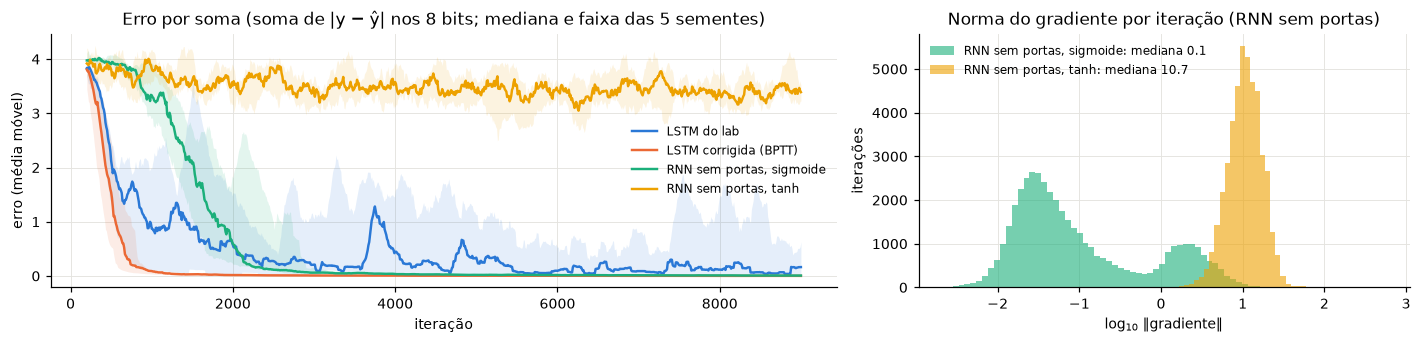

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
suave = lambda e: np.convolve(e, np.ones(20) / 20, mode='valid')
for i, (nome, res) in enumerate(bin_res.items()):
    curvas = np.array([suave(e) for _, e, _ in res])
    it = (np.arange(curvas.shape[1]) + 20) * 10
    ax[0].plot(it, np.median(curvas, 0), color=COR[i], lw=1.6, label=nome)
    ax[0].fill_between(it, curvas.min(0), curvas.max(0), color=COR[i], alpha=0.12, lw=0)
ax[0].set(title='Erro por soma (soma de |y − ŷ| nos 8 bits; mediana e faixa das 5 sementes)', xlabel='iteração', ylabel='erro (média móvel)')
ax[0].legend(fontsize=8)
for i, nome in enumerate(['RNN sem portas, sigmoide', 'RNN sem portas, tanh']):
    nrm = np.concatenate([n for _, _, n in bin_res[nome]])
    ax[1].hist(np.log10(nrm), bins=60, color=COR[2 + i], alpha=0.6, label=f'{nome}: mediana {np.median(nrm):.1f}')
ax[1].set(title='Norma do gradiente por iteração (RNN sem portas)', xlabel='log$_{10}$ ‖gradiente‖', ylabel='iterações')
ax[1].legend(fontsize=8)
plt.tight_layout()

* **LSTM do lab (tradução fiel).** A rede aprende a somar: na semente 0, acerta 98,3 % das 16 256 somas e 99,7 % dos bits. Mas o treino é instável, com recaídas perto das iterações 4000 e 5000 (também visíveis na impressão acima), e varia muito entre sementes: de 82 % a 100 % de somas exatas. Em 16 bits, o acerto cai para 62–99 %.
* **LSTM corrigida (BPTT).** Converge em cerca de 1000 iterações, sem recaídas, e acerta 100 % das somas em todas as sementes. Também **generaliza para 16 bits sem retreino** (100 %): a mesma célula é aplicada em cada posição, então aprender a regra do vai-um vale para números de qualquer tamanho.
* **RNN sem portas, sigmoide.** Também chega a 100 % em 8 e em 16 bits, só que mais devagar (cerca de 3000 iterações). Isso é esperado: o vai-um é uma dependência de **um passo**, curta demais para o gradiente de uma RNN simples desaparecer. A vantagem decisiva da LSTM aparece em dependências longas, de dezenas a centenas de passos. Nesse caso, o estado de célula aditivo $\mathbf C_t = \mathbf f_t\odot\mathbf C_{t-1} + \mathbf g_t\odot\mathbf i_t$ deixa o erro fluir para trás sem ser multiplicado a cada passo por $\mathbf R$ e pela derivada da ativação.
* **RNN sem portas, tanh.** Não aprende: acerta 0,6 % das somas e 58 % dos bits, pouco acima do acaso (50 %). Com a mesma inicialização $U(-1, 1)$ e o mesmo $\alpha = 0{,}1$, a norma do gradiente é cerca de 100 vezes maior que na versão sigmoide (mediana de 10,7 contra 0,1; histograma à direita), porque a derivada da tanh chega a 1, e a da sigmoide, a 0,25. Cada passo é grande demais, o mesmo tipo de instabilidade da seção 3.6. A LSTM, que também tem tanh internas, treinou com o mesmo $\alpha$.

**Onde a LSTM do lab erra?** A tabela mostra, para cada semente, com que frequência $|C_t| > 1$, caso em que a "derivada" $1 - C_t^2$ do `.m` fica negativa. Mostra também a taxa de erro por bit em 16 bits, separada pelo comprimento da cadeia de vai-um que chega àquele bit (0 = não chega vai-um).

In [23]:
def cadeia(A, B, nb):
    # comprimento da cadeia de vai-um que chega a cada bit (quantas posições seguidas o vai-um já percorreu)
    a, b = bits(A, nb), bits(B, nb)
    c, L, out = np.zeros(len(A), int), np.zeros(len(A), int), np.zeros_like(a)
    for t in range(nb):
        out[:, t] = np.where(c == 1, L, 0)
        novo = (a[:, t] + b[:, t] + c >= 2).astype(int)
        L = np.where(novo == 1, np.where(c == 1, L + 1, 1), 0)
        c = novo
    return out


faixas = {'0': (0, 0), '1': (1, 1), '2–3': (2, 3), '4–7': (4, 7), '≥ 8': (8, 99)}
linhas = []
for nome in ['LSTM do lab', 'LSTM corrigida (BPTT)']:
    for s, (p, _, _) in zip(SEMENTES, bin_res[nome]):
        _, (_, _, _, st) = avalia(lstm_forward, p)
        C = np.concatenate([c.ravel() for c in st['C'][1:]])
        res16, (A, B, pred, _) = avalia(lstm_forward, p, 16, n=20_000)
        erro, cad = np.round(pred).astype(int) != bits(A + B, 16), cadeia(A, B, 16)
        linha = {'modelo': nome, 'semente': s, '|C| > 1 (% dos passos, 8 bits)': f'{100 * np.mean(np.abs(C) > 1):.1f}',
                 '16 bits: somas exatas (%)': f"{res16['somas exatas (%)']:.1f}"}
        for rot, (lo, hi) in faixas.items():
            linha[f'erro de bit (%), cadeia {rot}'] = f'{100 * erro[(cad >= lo) & (cad <= hi)].mean():.2f}'
        linhas.append(linha)
display(pd.DataFrame(linhas).set_index(['modelo', 'semente']))

|C| > 1 (% dos passos, 8 bits)  \
modelo                semente                                  
LSTM do lab           0                                 18.2   
                      1                                 41.7   
                      2                                 38.8   
                      3                                 53.0   
                      4                                  7.8   
LSTM corrigida (BPTT) 0                                 12.9   
                      1                                 19.8   
                      2                                 19.1   
                      3                                 23.2   
                      4                                  6.0   

                              16 bits: somas exatas (%)  \
modelo                semente                             
LSTM do lab           0                            85.0   
                      1                            89.2   
                      2                            87.8   
                      3                            62.4   
                      4                            98.8   
LSTM corrigida (BPTT) 0                           100.0   
                      1                           100.0   
                      2                            99.9   
                      3                           100.0   
                      4                           100.0   

                              erro de bit (%), cadeia 0  \
modelo                semente                             
LSTM do lab           0                            2.22   
                      1                            1.69   
                      2                            0.14   
                      3                            4.27   
                      4                            0.20   
LSTM corrigida (BPTT) 0                            0.00   
                      1                            0.00   
                      2                            0.01   
                      3                            0.00   
                      4                            0.00   

                              erro de bit (%), cadeia 1  \
modelo                semente                             
LSTM do lab           0                            0.38   
                      1                            0.21   
                      2                            0.16   
                      3                            0.00   
                      4                            0.00   
LSTM corrigida (BPTT) 0                            0.00   
                      1                            0.00   
                      2                            0.00   
                      3                            0.00   
                      4                            0.00   

                              erro de bit (%), cadeia 2–3  \
modelo                semente                               
LSTM do lab           0                              0.95   
                      1                              0.08   
                      2                              2.45   
                      3                              0.50   
                      4                              0.01   
LSTM corrigida (BPTT) 0                              0.00   
                      1                              0.00   
                      2                              0.00   
                      3                              0.00   
                      4                              0.00   

                              erro de bit (%), cadeia 4–7  \
modelo                semente                               
LSTM do lab           0                              3.00   
                      1                              0.18   
                      2                              6.49   
                      3                             12.72   
                      4            

* **A derivada errada inverte o passo.** Na LSTM do lab, $|C_t| > 1$ em 8 % a 53 % dos passos, conforme a semente. Nesses passos, $1 - C_t^2 < 0$, e a atualização no caminho da célula aponta no sentido **contrário** ao do gradiente. Junto com a retropropagação truncada, isso explica as recaídas do treino e a variação entre sementes. A semente com menos passos nessa situação (4, com 8 %) é justamente a que mais acerta em 16 bits (98,8 %). Na versão corrigida, $|C_t| > 1$ também ocorre, mas não causa problema, porque a derivada $1 - \tanh^2(C_t)$ é sempre positiva.
* **Cadeias longas de vai-um.** Nas sementes 2 e 3, o erro por bit sobe de no máximo 2,5 % em cadeias de 1 a 3 posições para 6 % a 17 % em cadeias de 4 ou mais. Sem gradiente através do tempo, nada obriga o estado a *guardar* o vai-um por muitos passos, e as cadeias longas, raras nas somas de 8 bits do treino, expõem a falha. Há também erros sem nenhum vai-um chegando (cadeia 0: 2 % a 4 % nas sementes 0 e 3), ou seja, um vai-um "fantasma" que a rede não apaga. A LSTM corrigida praticamente não erra em nenhuma faixa (no máximo 0,01 %).

### 4.3 O que a LSTM aprendeu?

Para cada unidade, mede-se a correlação entre $h_t$ e o bit de vai-um gerado no passo $t$, usando as 16 256 somas. A figura mostra a soma $16383 + 1 = 16384$ em 16 bits. Ela gera uma cadeia de vai-um de 14 posições, mais longa que qualquer uma das somas de 8 bits do treino.

LSTM do lab           : unidade  1, correlação com o vai-um = +0.641; leitura linear de h_t acerta o vai-um em 99.84% dos passos


LSTM corrigida (BPTT) : unidade 13, correlação com o vai-um = -0.965; leitura linear de h_t acerta o vai-um em 100.00% dos passos


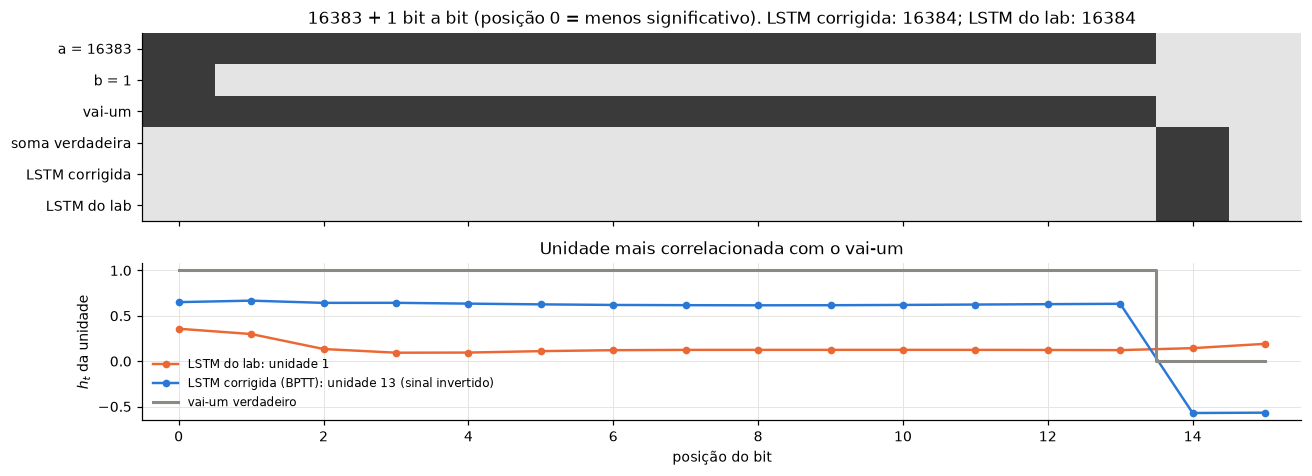

In [24]:
def carry(A, B, nb):
    a, b, c = bits(A, nb), bits(B, nb), np.zeros(len(A), int)
    out = np.zeros_like(a)
    for t in range(nb):
        c = (a[:, t] + b[:, t] + c >= 2).astype(int)
        out[:, t] = c
    return out


unidades = {}
for nome in ['LSTM do lab', 'LSTM corrigida (BPTT)']:
    p = bin_res[nome][0][0]                                              # semente 0
    _, (A, B, _, st) = avalia(lstm_forward, p)
    Hs = np.stack(st['H'][1:], 1).reshape(-1, p['Hi'].shape[0])
    cy = carry(A, B, BITS).ravel()
    corr = np.array([np.corrcoef(Hs[:, k], cy)[0, 1] for k in range(Hs.shape[1])])
    k = int(np.nanargmax(np.abs(corr)))
    X1 = np.c_[Hs, np.ones(len(Hs))]
    w = np.linalg.lstsq(X1, 2 * cy - 1, rcond=None)[0]                   # leitura linear do vai-um a partir de h_t
    unidades[nome] = (p, k, np.sign(corr[k]))
    print(f'{nome:22s}: unidade {k:2d}, correlação com o vai-um = {corr[k]:+.3f}; '
          f'leitura linear de h_t acerta o vai-um em {100 * np.mean((X1 @ w > 0) == cy):.2f}% dos passos')

A, B = np.array([16383]), np.array([1])
X = np.stack([bits(A, 16), bits(B, 16)], -1).astype(float)
fig, ax = plt.subplots(2, 1, figsize=(12, 4.4), sharex=True, gridspec_kw=dict(height_ratios=[1.2, 1]))
pred_bptt = np.round(lstm_forward(unidades['LSTM corrigida (BPTT)'][0], X)[0][0]).astype(int)
pred_lab = np.round(lstm_forward(unidades['LSTM do lab'][0], X)[0][0]).astype(int)
M = np.vstack([bits(A, 16)[0], bits(B, 16)[0], carry(A, B, 16)[0], bits(A + B, 16)[0], pred_bptt, pred_lab])
ax[0].imshow(M, cmap='Greys', vmin=-0.3, vmax=1.3, aspect='auto')
ax[0].set_yticks(range(6), ['a = 16383', 'b = 1', 'vai-um', 'soma verdadeira', 'LSTM corrigida', 'LSTM do lab'])
ax[0].set_title(f'16383 + 1 bit a bit (posição 0 = menos significativo). LSTM corrigida: {para_int(pred_bptt)}; LSTM do lab: {para_int(pred_lab)}')
ax[0].grid(False)
for i, (nome, (p, k, sinal)) in enumerate(unidades.items()):
    _, st = lstm_forward(p, X)
    ax[1].plot(range(16), sinal * np.array([h[0, k] for h in st['H'][1:]]), color=COR[1 - i], lw=1.6, marker='o', ms=4,
               label=f'{nome}: unidade {k}' + (' (sinal invertido)' if sinal < 0 else ''))
ax[1].step(range(16), carry(A, B, 16)[0], where='mid', color=VERD, lw=2, label='vai-um verdadeiro')
ax[1].set(xlabel='posição do bit', ylabel='$h_t$ da unidade', title='Unidade mais correlacionada com o vai-um')
ax[1].legend(fontsize=8, loc='lower left')
plt.tight_layout()

* Na LSTM corrigida, **uma única unidade** (a 13) tem correlação de −0,965 com o vai-um. Na soma 16383 + 1, ela fica num patamar constante durante os 14 passos em que o vai-um se propaga e muda de sinal quando ele termina, como um *flip-flop*. A rede descobriu sozinha o registrador de vai-um de um somador serial, e é por isso que a regra vale para qualquer número de bits.
* Na LSTM do lab, a informação também existe, mas é distribuída e mais fraca: a melhor unidade tem correlação de 0,64, e só a combinação linear de todas as unidades recupera o vai-um (99,84 % dos passos). Sem BPTT, o estado não é treinado para guardar o vai-um; a informação aparece como subproduto do treino local de cada passo.

## 5. Conclusões

1. **Reprodução do lab.** A `layrecnet(1, 10, 'trainlm')` reescrita em NumPy recupera a refletividade do teste com NMSE ≈ 0,01, como na Fig. 1 do lab. O resultado depende da inicialização: de 0,004 a 0,22 entre 5 sementes.
2. **Tarefa (1).** Usada para imitar a convolução, a RNN fica presa em NMSE ≈ 0,32 e reproduz só a metade da wavelet que vem depois do spike. A causa é a **causalidade**: a Ricker de fase zero começa 10 amostras antes do spike, e uma RNN unidirecional não responde a entradas futuras. A rede converge exatamente para o melhor preditor causal ($w_c * r$, NMSE 0,318). Com 10 amostras de antecipação, reproduz a wavelet inteira (NMSE $2\times10^{-6}$).
3. **Tarefa (2).**
   * A capacidade mínima fica entre 2 e 5 neurônios. Mais neurônios, mais atrasos de realimentação e antecipação $D$ reduzem o erro, até $10^{-5}$–$10^{-6}$; a profundidade não ajudou.
   * Sem recorrência, a rede não deconvolve (NMSE ≈ 0,5): a memória é essencial.
   * O algoritmo de treino pesou mais que a arquitetura. O `trainlm` chega a $10^{-4}$ em cerca de 50 épocas. O `traingd` com o `lr = 0.05` do lab quase não avança em 500 épocas, e com lr = 0,5 diverge. A parada antecipada, com dados sem ruído, só atrapalhou.
   * Cerca de 7 % dos treinos falham por explosão do gradiente, por isso é preciso treinar várias inicializações.
   * Erro baixo no teste do lab não garante uma boa deconvolução. As redes degradam com eventos interferentes, ruído e, sobretudo, outra wavelet, e uma delas aprendeu a paridade do instante de amostragem em vez da física.
4. **Tarefa (3).** A LSTM do lab aprende a somar (95 % das somas exatas, em média), mas seu código tem retropropagação truncada em um passo e uma derivada errada que inverte o passo quando $|C_t| > 1$. Com as duas correções, a LSTM acerta 100 %, generaliza para 16 bits e dedica uma unidade ao vai-um. Como a dependência do problema é de um passo, uma RNN sem portas com sigmoide também o resolve; com tanh e o mesmo $\alpha$, o gradiente explode. A vantagem da LSTM aparece em dependências longas, que nem a soma binária nem a deconvolução do lab (wavelet de cerca de 20 amostras) exigem.